# Aula 02 — Fundamentos de IA e Aprendizado de Máquina

- **Disciplina:** IBM3116 — Métodos e Aplicações de IA · Engenharia da Computação e de Software
- **Professor:** Carlos Eduardo Leal de Castro

---

**Como usar:** execute as células na ordem em que aparecem (`Kernel → Restart & Run All` deve funcionar
do início ao fim). As células marcadas com `# TODO` são suas: elas **não** possuem solução no notebook.

**Entrega:** este notebook, com todos os exercícios preenchidos e executados, compõe a nota de AC.

## 1. Por que estudar isso?

Considere um problema real de Engenharia da Computação. Uma linha de produção possui **motores elétricos**
instrumentados com acelerômetros. Cada motor envia, a cada minuto, o valor RMS da vibração medida
(em mm/s). Quando um rolamento começa a se deteriorar, a vibração aumenta — mas ela também aumenta
quando a carga do motor sobe, quando a temperatura ambiente muda, quando o motor é religado.

Sua tarefa: **avisar a manutenção antes que o motor quebre**, sem gerar tantos alarmes falsos que a
equipe passe a ignorar o sistema.

A abordagem clássica de engenharia é escrever uma regra:

```python
if rms > 2.5:
    alarme()
```

Essa regra tem três problemas práticos:

1. **De onde veio o número 2.5?** Normalmente de um especialista, de uma norma, ou de tentativa e erro.
2. **O que acontece quando há 12 sensores em vez de 1?** A regra vira uma árvore de `if` com dezenas
   de limiares que ninguém consegue mais ajustar coerentemente.
3. **O que acontece quando o processo muda?** Novo lote de rolamentos, nova rotação nominal, novo turno —
   e o limiar precisa ser reescrito.

O **Aprendizado de Máquina** propõe uma inversão: em vez de o engenheiro escrever a regra, ele escreve
um **procedimento que extrai a regra a partir de dados históricos rotulados**. O limiar `2.5` deixa de ser
uma opinião e passa a ser o resultado de um problema de otimização, com um critério explícito que podemos
discutir, medir e criticar.

Esta aula responde a três perguntas que sustentam todo o resto da disciplina:

1. **O que exatamente é "aprender" a partir de dados?** (formalização)
2. **Quais tipos de problema de aprendizado existem?** (taxonomia)
3. **Quais etapas compõem um projeto de ML, e onde estão os erros que invalidam um resultado?** (pipeline)

E, como esta é uma disciplina de implementação, ela também garante que o seu ambiente de trabalho esteja
funcionando e seja **reprodutível**.

## 3. Onde este tema está dentro da Inteligência Artificial?

**Inteligência Artificial (IA)** é o campo que estuda a construção de agentes que percebem um ambiente e
agem sobre ele para atingir objetivos. É um campo amplo e antigo: busca heurística, lógica e representação
do conhecimento, planejamento, raciocínio sob incerteza, processamento de linguagem natural, robótica e
**aprendizado**. Nem toda IA aprende: um solucionador de xadrez por busca `alpha-beta` com função de
avaliação escrita à mão é IA, e não é ML.

**Aprendizado de Máquina (ML)** é o subcampo da IA que estuda algoritmos cujo desempenho em uma tarefa
melhora com a **experiência** (dados). É onde está praticamente toda esta disciplina.

**Aprendizado Profundo (Deep Learning)** é o subconjunto do ML que usa redes neurais com múltiplas camadas
de representação, aprendidas conjuntamente. É o assunto das últimas aulas do semestre.

```
┌──────────────────────────────────────────────────────────────┐
│ Inteligência Artificial                                      │
│   busca · lógica · planejamento · representação · agentes    │
│  ┌────────────────────────────────────────────────────────┐  │
│  │ Aprendizado de Máquina                                 │  │
│  │   supervisionado · não supervisionado · por reforço    │  │
│  │  ┌──────────────────────────────────────────────────┐  │  │
│  │  │ Aprendizado Profundo                             │  │  │
│  │  │   MLP · CNN · RNN · Transformers                 │  │  │
│  │  └──────────────────────────────────────────────────┘  │  │
│  └────────────────────────────────────────────────────────┘  │
└──────────────────────────────────────────────────────────────┘
```

Um erro comum é tratar essas três palavras como sinônimos. Elas não são, e a distinção tem consequência
prática: para o problema do motor, uma regressão logística com quatro atributos pode resolver o caso melhor
do que uma rede profunda — que exigiria muito mais dados, mais tempo de treinamento e daria uma explicação
menos auditável para a equipe de manutenção.

**Onde as próximas aulas se encaixam:** a partir da aula 3 entramos em aprendizado supervisionado
(regressão linear, regressão logística, KNN, árvores, ensembles), depois em avaliação rigorosa e engenharia
de dados, depois em aprendizado não supervisionado (k-means, PCA) e finalmente em redes neurais.
Esta aula é o mapa desse percurso e, principalmente, o conjunto de hábitos experimentais que usaremos
em todas as demais.

## 4. Pré-requisitos

### 4.1 Vetores e matrizes de dados

Uma observação (uma leitura de sensor, um paciente, um pacote de rede) é um vetor de $p$ atributos:

$$\mathbf{x}_i = (x_{i1}, x_{i2}, \dots, x_{ip})^{\top} \in \mathbb{R}^{p}.$$

Um conjunto de $n$ observações é empilhado em uma **matriz de projeto** $\mathbf{X} \in \mathbb{R}^{n \times p}$,
com uma observação por **linha** e um atributo por **coluna**. Essa convenção (linha = amostra) é a usada por
NumPy, pandas, scikit-learn e PyTorch; violá-la é uma das fontes mais comuns de erro de dimensão.

### 4.2 Distância euclidiana

A distância entre duas observações no espaço de atributos:

$$d(\mathbf{a}, \mathbf{b}) = \|\mathbf{a} - \mathbf{b}\|_2 = \sqrt{\sum_{j=1}^{p} (a_j - b_j)^2}.$$

Ela será usada hoje no classificador que vamos implementar, e é central em KNN e k-means.
Note desde já: a distância **soma contribuições de atributos em unidades diferentes**
(mm/s, °C, horas). Isso terá consequências.

### 4.3 Média como minimizador do erro quadrático

Um fato pequeno e muito útil. Dado um conjunto de valores $\{z_1,\dots,z_m\}$, o número $c$ que minimiza

$$J(c) = \sum_{i=1}^{m} (z_i - c)^2$$

é a **média** $\bar{z}$. Basta derivar: $J'(c) = -2\sum_i (z_i - c) = 0 \Rightarrow c = \frac{1}{m}\sum_i z_i$.

Guarde isso: quando escolhemos o erro quadrático como critério, a média deixa de ser uma convenção
estatística e passa a ser **a solução de um problema de otimização**. Esse é exatamente o raciocínio que
reaparece na regressão linear (aula 3) e no k-means.

## 5. Configuração e verificação do ambiente

Todo resultado desta disciplina precisa ser **reprodutível**: outra pessoa, em outra máquina, deve obter
os mesmos números. Isso exige controlar três coisas — o interpretador, as versões das bibliotecas e as
sementes aleatórias.

### 5.1 Ambiente isolado (uma vez por máquina)

No terminal (Anaconda Prompt no Windows, terminal no Linux/macOS):

```bash
conda create -n ia2026 python=3.11 -y
conda activate ia2026
pip install numpy pandas matplotlib scikit-learn jupyterlab ipykernel
python -m ipykernel install --user --name ia2026 --display-name "Python (ia2026)"
```

O último comando registra o ambiente como um **kernel** do Jupyter. No VSCode, use o seletor de kernel no
canto superior direito e escolha `Python (ia2026)` — é o erro mais frequente do início do semestre executar
o notebook no Python do sistema, sem as bibliotecas instaladas.

O PyTorch só será necessário a partir da aula de redes neurais (29/10) e será instalado no momento oportuno.

### 5.2 Registro do ambiente

Para congelar o ambiente e permitir que ele seja recriado:

```bash
conda env export --from-history > environment.yml
```

e, em outra máquina:

```bash
conda env create -f environment.yml
```

### 5.3 Verificação

A célula abaixo é o seu teste de sanidade. Se ela falhar, resolva isso **antes** de continuar.

In [1]:
import sys
import platform

print("Python      :", sys.version.split()[0])
print("Executável  :", sys.executable)
print("Plataforma  :", platform.platform())
print("-" * 60)

import numpy
import pandas
import matplotlib
import sklearn

for modulo in (numpy, pandas, matplotlib, sklearn):
    print(f"{modulo.__name__:<12} {modulo.__version__}")

try:
    import torch
    print(f"{'torch':<12} {torch.__version__}")
except ImportError:
    print(f"{'torch':<12} não instalado (necessário apenas a partir da aula 29/10)")

Python      : 3.12.13
Executável  : c:\Users\Carlos\miniconda3\envs\ibmec\python.exe
Plataforma  : Windows-11-10.0.26200-SP0
------------------------------------------------------------
numpy        2.5.1
pandas       3.0.3
matplotlib   3.11.0
sklearn      1.9.0
torch        2.13.0+cu126


### 5.4 Sementes e determinismo

Muitos procedimentos que usaremos são estocásticos: a divisão treino/teste, a inicialização do k-means,
a ordem dos lotes no treinamento de uma rede. Sem controlar a fonte de aleatoriedade, **dois `Run All`
produzem números diferentes** e nenhuma comparação é confiável.

Duas práticas ao longo de todo o semestre:

- criar um gerador explícito com `np.random.default_rng(SEED)` em vez de usar `np.random.rand` global;
- passar `random_state=SEED` em toda função do scikit-learn que aceite esse argumento.

Fixar a semente **não elimina** a variabilidade do experimento — apenas a torna repetível. Voltaremos a
esse ponto na seção 10, quando mediremos o quanto um resultado muda ao trocar apenas a semente.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams["figure.figsize"] = (7.0, 4.2)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

# Duas chamadas ao MESMO gerador dão números diferentes (o estado avança);
# dois geradores criados com a mesma semente dão a mesma sequência.
g1 = np.random.default_rng(SEED)
g2 = np.random.default_rng(SEED)
print("g1:", np.round(g1.normal(size=3), 4))
print("g2:", np.round(g2.normal(size=3), 4), " <- idêntico, porque a semente é a mesma")
print("g1:", np.round(g1.normal(size=3), 4), " <- diferente, porque o estado de g1 avançou")

g1: [ 0.3047 -1.04    0.7505]
g2: [ 0.3047 -1.04    0.7505]  <- idêntico, porque a semente é a mesma
g1: [ 0.9406 -1.951  -1.3022]  <- diferente, porque o estado de g1 avançou


## 6. De regras escritas a regras induzidas

Voltemos ao motor. Vamos construir um conjunto de dados histórico realista para o problema: leituras de
vibração RMS de motores que, no dia seguinte, apresentaram ou não falha de rolamento.

Os dados são **sintéticos** e gerados aqui mesmo — isso é uma escolha pedagógica deliberada: como
conhecemos o processo que os gerou, podemos verificar se o que o algoritmo "descobriu" corresponde à
realidade. Com dados reais isso é impossível, e é justamente por isso que a avaliação precisa ser rigorosa.

In [3]:
def gerar_leituras_vibracao(n_ok=400, n_falha=120, seed=SEED):
    """Gera leituras de vibração RMS (mm/s) de motores.

    Processo gerador (conhecido apenas porque os dados são sintéticos):
      - motor saudável : RMS ~ Normal(1.8, 0.35)
      - motor com falha: RMS ~ Normal(3.0, 0.60)
    Retorna (x, y) com y = 1 indicando falha no dia seguinte.
    """
    r = np.random.default_rng(seed)
    rms_ok = r.normal(1.80, 0.35, n_ok)
    rms_falha = r.normal(3.00, 0.60, n_falha)

    x = np.concatenate([rms_ok, rms_falha])
    y = np.concatenate([np.zeros(n_ok, dtype=int), np.ones(n_falha, dtype=int)])

    ordem = r.permutation(len(x))          # embaralha para não deixar as classes agrupadas
    return x[ordem], y[ordem]


x_rms, y_falha = gerar_leituras_vibracao()

print("n observações :", x_rms.shape[0])
print("falhas        :", y_falha.sum(), f"({y_falha.mean():.1%} do total)")
print("RMS  min/média/max:", f"{x_rms.min():.2f} / {x_rms.mean():.2f} / {x_rms.max():.2f}")

n observações : 520
falhas        : 120 (23.1% do total)
RMS  min/média/max: 0.90 / 2.07 / 4.56


### 6.1 A regra escrita à mão

Um especialista sugere `alarme se RMS > 2.5`. Vamos medir o que essa regra faz nos dados históricos.
Definimos o **erro** como a fração de leituras classificadas incorretamente:

$$\text{erro}(\tau) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\!\left[\,\mathbb{1}[x_i > \tau] \neq y_i\,\right],$$

em que $\tau$ é o limiar, $\mathbb{1}[\cdot]$ é a função indicadora (vale 1 se a condição é verdadeira,
0 caso contrário), $x_i$ é a leitura RMS e $y_i \in \{0,1\}$ o rótulo observado.

In [4]:
def erro_do_limiar(tau, x, y):
    """Fração de classificações incorretas da regra 'alarme se x > tau'."""
    previsao = (x > tau).astype(int)
    return np.mean(previsao != y)


tau_especialista = 2.5
print(f"Regra do especialista (tau = {tau_especialista}):  erro = {erro_do_limiar(tau_especialista, x_rms, y_falha):.4f}")

Regra do especialista (tau = 2.5):  erro = 0.0654


### 6.2 A regra induzida a partir dos dados

Agora a inversão. Em vez de **escolher** $\tau$, vamos **procurá-lo**: definimos o critério (o erro acima)
e deixamos que o valor de $\tau$ seja aquele que minimiza esse critério sobre os dados históricos:

$$\tau^{*} = \arg\min_{\tau} \; \text{erro}(\tau).$$

Este é, em miniatura, todo o Aprendizado de Máquina supervisionado: **um modelo com parâmetros, um
critério mensurável e um procedimento de otimização**. Aqui o modelo tem um único parâmetro e o espaço de
busca é unidimensional, então podemos varrer todos os candidatos por força bruta. Nas próximas aulas,
com milhares de parâmetros, a busca exaustiva se torna impossível e usaremos o gradiente descendente.

In [5]:
candidatos = np.linspace(x_rms.min(), x_rms.max(), 500)
erros = np.array([erro_do_limiar(t, x_rms, y_falha) for t in candidatos])

tau_otimo = candidatos[np.argmin(erros)]
erro_otimo = erros.min()

print(f"tau* encontrado : {tau_otimo:.3f}")
print(f"erro em tau*    : {erro_otimo:.4f}")
print(f"erro em tau=2.5 : {erro_do_limiar(2.5, x_rms, y_falha):.4f}")

tau* encontrado : 2.463
erro em tau*    : 0.0577
erro em tau=2.5 : 0.0654


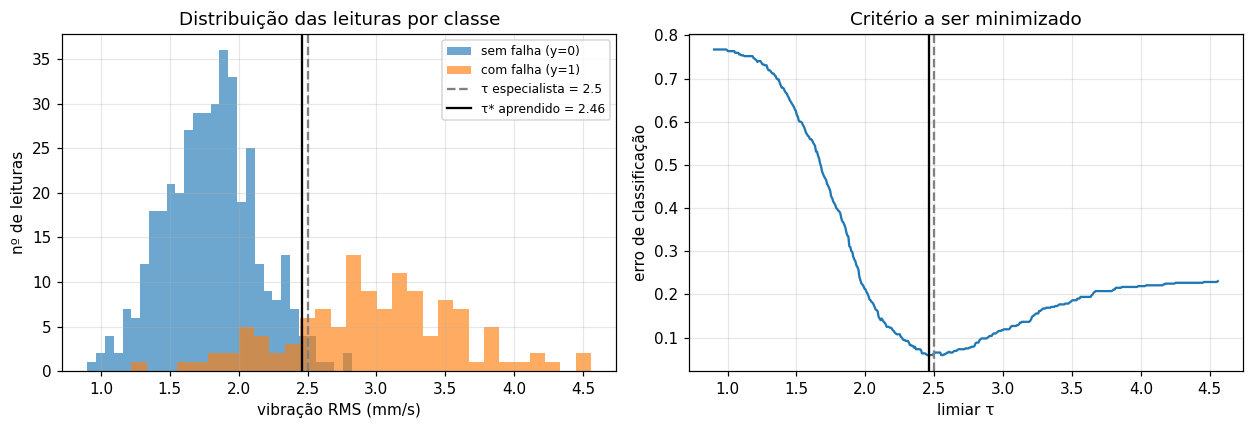

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0))

ax1.hist(x_rms[y_falha == 0], bins=30, alpha=0.65, label="sem falha (y=0)")
ax1.hist(x_rms[y_falha == 1], bins=30, alpha=0.65, label="com falha (y=1)")
ax1.axvline(2.5, linestyle="--", color="gray", label="τ especialista = 2.5")
ax1.axvline(tau_otimo, linestyle="-", color="black", label=f"τ* aprendido = {tau_otimo:.2f}")
ax1.set_xlabel("vibração RMS (mm/s)")
ax1.set_ylabel("nº de leituras")
ax1.set_title("Distribuição das leituras por classe")
ax1.legend(fontsize=8)

ax2.plot(candidatos, erros)
ax2.axvline(tau_otimo, linestyle="-", color="black")
ax2.axvline(2.5, linestyle="--", color="gray")
ax2.set_xlabel("limiar τ")
ax2.set_ylabel("erro de classificação")
ax2.set_title("Critério a ser minimizado")

plt.tight_layout()
plt.show()

### O que acabamos de observar?

Três leituras do gráfico, e nenhuma delas é óbvia:

1. **As distribuições se sobrepõem.** Existem motores saudáveis com RMS alto e motores prestes a falhar com
   RMS baixo. Isso significa que **nenhum limiar atinge erro zero** — há um piso de erro imposto pelos
   dados, não pelo algoritmo. Nenhuma quantidade de esforço computacional remove essa sobreposição; só
   mais informação (outros sensores) removeria.

2. **A curva de erro não é suave.** Ela é uma função escada: só muda quando $\tau$ cruza uma observação.
   Isso a torna não diferenciável — e é exatamente por isso que, mais adiante, substituiremos o "erro de
   classificação" por funções de custo suaves (entropia cruzada), que admitem gradiente.

3. **O mínimo é uma região, não um ponto.** Vários valores de $\tau$ dão o mesmo erro. O valor exato de
   `tau_otimo` depende da grade de candidatos que escolhemos — ele não é um número sagrado.

E há uma quarta observação, mais importante que as três: **medimos o erro nos mesmos dados usados para
escolher $\tau$**. Esse número é otimista por construção. Corrigir isso é o assunto da seção 8.

## Exercício 1 — O custo de errar não é simétrico

**Objetivo:** perceber que o "critério a ser minimizado" é uma decisão de engenharia, não uma constante universal.

**Contexto:** na fábrica, um **falso negativo** (não avisar um motor que vai falhar) custa R\$ 20.000 em
parada não programada. Um **falso positivo** (parar um motor saudável para inspeção) custa R\$ 500.
A regra que minimiza o *número* de erros não minimiza o *custo*.

**Tarefa:**
1. Implemente `custo_do_limiar(tau, x, y, custo_fn=20000, custo_fp=500)`, que devolve o custo **total**
   da regra `alarme se x > tau` sobre o conjunto (conte falsos negativos e falsos positivos e multiplique
   pelos respectivos custos).
2. Varra a mesma grade de candidatos e encontre $\tau_{\text{custo}}$ que minimiza o custo.
3. Compare $\tau_{\text{custo}}$ com $\tau^{*}$: qual é maior? Explique o sinal da diferença **antes** de
   olhar o número, a partir da assimetria dos custos.
4. Reporte, para os dois limiares, o custo total e o número de erros.

**Entregável:** a implementação, o gráfico do custo em função de $\tau$ e um parágrafo justificando
por que os dois critérios levam a limiares diferentes.

In [ ]:
# Exercício 1 — o critério a minimizar é uma decisão de engenharia.

def custo_do_limiar(tau, x, y, custo_fn=20_000, custo_fp=500):
    """Custo total (em R$) da regra 'alarme se x > tau'."""
    previsao = (x > tau).astype(int)
    fn = np.sum((previsao == 0) & (y == 1))   # ia falhar e não alarmamos
    fp = np.sum((previsao == 1) & (y == 0))   # alarme em motor saudável
    return fn * custo_fn + fp * custo_fp


# 2) varredura da MESMA grade de candidatos usada para minimizar o erro
custos = np.array([custo_do_limiar(t, x_rms, y_falha) for t in candidatos])
tau_custo = candidatos[np.argmin(custos)]

# 4) relatório dos dois limiares (mais o do especialista, como referência)
def resumo(tau, rotulo):
    previsao = (x_rms > tau).astype(int)
    fn = int(np.sum((previsao == 0) & (y_falha == 1)))
    fp = int(np.sum((previsao == 1) & (y_falha == 0)))
    print(f"{rotulo:<26} tau={tau:5.3f} | FN={fn:3d} | FP={fp:3d} | "
          f"erros={fn + fp:3d} ({(fn + fp) / len(y_falha):6.2%}) | custo = R$ {fn * 20_000 + fp * 500:>9,}")

print("n =", len(y_falha), "leituras;", int(y_falha.sum()), "falhas reais\n")
resumo(2.5, "especialista (tau=2.5)")
resumo(tau_otimo, "tau* (minimiza o ERRO)")
resumo(tau_custo, "tau_custo (minimiza o CUSTO)")

custo_tau_otimo = custo_do_limiar(tau_otimo, x_rms, y_falha)
print(f"\neconomia de tau_custo sobre tau*: R$ {custo_tau_otimo - custos.min():,}"
      f"  ({1 - custos.min() / custo_tau_otimo:.1%} de redução)")

# Limiar teórico: alarmar quando o custo esperado de não alarmar supera o de alarmar,
# isto é, quando  P(falha | x) > custo_fp / (custo_fp + custo_fn).
p_corte = 500 / (500 + 20_000)
print(f"\nrazão de custos FN:FP = {20_000 / 500:.0f}:1")
print(f"probabilidade de falha a partir da qual vale alarmar: {p_corte:.4f} ({p_corte:.2%})")

# 3) gráfico: os dois critérios sobre a mesma grade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0))

ax1.plot(candidatos, erros, color="tab:blue")
ax1.axvline(tau_otimo, color="black", label=f"τ* = {tau_otimo:.2f}")
ax1.axvline(tau_custo, color="tab:red", ls="--", label=f"τ_custo = {tau_custo:.2f}")
ax1.set_xlabel("limiar τ"); ax1.set_ylabel("erro de classificação")
ax1.set_title("Critério 1: número de erros"); ax1.legend(fontsize=8)

ax2.plot(candidatos, custos / 1000, color="tab:red")
ax2.axvline(tau_otimo, color="black", label=f"τ* = {tau_otimo:.2f}")
ax2.axvline(tau_custo, color="tab:red", ls="--", label=f"τ_custo = {tau_custo:.2f}")
ax2.set_xlabel("limiar τ"); ax2.set_ylabel("custo total (R$ mil)")
ax2.set_title("Critério 2: custo assimétrico (FN=20k, FP=500)"); ax2.legend(fontsize=8)

plt.tight_layout(); plt.show()

> **Análise do Exercício 1:**

**Previsão antes de olhar o número (item 3).** Um falso negativo custa **40× mais** que um falso positivo. Como baixar o limiar troca falsos negativos por falsos positivos, e cada troca dessas rende R\$ 20.000 de economia contra R\$ 500 de despesa, o limiar que minimiza o custo tem de ser **menor** que $\tau^{*}$ — o sistema deve ficar deliberadamente "paranoico". O sinal da diferença é previsível sem rodar nada; só a magnitude não é.

**Resultados.**

| limiar | FN | FP | erros | custo total |
|:--|--:|--:|--:|--:|
| especialista, $\tau=2{,}5$ | 26 | 8 | 34 (6,54%) | R\$ 524.000 |
| $\tau^{*} = 2{,}463$ (minimiza o erro) | 21 | 9 | 30 (5,77%) | R\$ 424.500 |
| $\tau_{\text{custo}} = 1{,}752$ (minimiza o custo) | **2** | 220 | 222 (42,69%) | **R\$ 150.000** |

**Por que os dois critérios levam a limiares tão diferentes.** O erro de classificação é a perda 0–1: ele atribui peso 1 a todo engano, seja qual for. O custo é uma perda **assimétrica**, com pesos 20.000 e 500. Minimizar um não minimiza o outro — são funções objetivo diferentes sobre o mesmo modelo e os mesmos dados, e portanto têm mínimos em lugares diferentes. O resultado é contraintuitivo à primeira vista: $\tau_{\text{custo}}$ comete **7,4 vezes mais erros** que $\tau^{*}$ (222 contra 30) e mesmo assim custa **65% menos** (R\$ 150 mil contra R\$ 424,5 mil), porque troca 19 falsos negativos caríssimos por 211 falsos positivos baratos.

**A regra por trás do número.** A decisão ótima é alarmar quando o custo esperado de silenciar supera o de alarmar:

$$P(\text{falha}\mid x)\cdot c_{FN} \;>\; \bigl(1 - P(\text{falha}\mid x)\bigr)\cdot c_{FP}
\quad\Longleftrightarrow\quad
P(\text{falha}\mid x) \;>\; \frac{c_{FP}}{c_{FP}+c_{FN}} = \frac{500}{20\,500} \approx 0{,}0244 .$$

Basta **2,4%** de probabilidade de falha para valer a pena inspecionar. É por isso que $\tau_{\text{custo}}$ cai para uma região em que a maioria dos motores é saudável.

**A ressalva de engenharia.** Alarmar 220 dos 400 motores saudáveis é ótimo *neste modelo de custos*, mas provavelmente inviável na fábrica: a equipe de manutenção tem capacidade finita e, com 42% de alarmes, passa a ignorar o sistema — a "fadiga de alarme" é um custo real que não está na conta de R\$ 500. Isso não invalida o método; mostra que **a função de custo precisa modelar o problema inteiro** (incluindo a restrição de capacidade e o custo de credibilidade). Fixar `custo_fp = 500` foi uma escolha nossa, e é ela — não a matemática — que deve ser discutida com a operação.

## 7. Formalização do aprendizado supervisionado

O exemplo do limiar contém, em escala mínima, todos os objetos que usaremos no semestre. Vamos nomeá-los.

### 7.1 Os dados

$$\mathcal{D} = \left\{ (\mathbf{x}_i, y_i) \right\}_{i=1}^{n}, \qquad \mathbf{x}_i \in \mathbb{R}^{p}.$$

- $n$ — número de observações (linhas de $\mathbf{X}$);
- $p$ — número de atributos (colunas de $\mathbf{X}$);
- $\mathbf{x}_i \in \mathbb{R}^{p}$ — vetor de atributos da $i$-ésima observação;
- $y_i$ — o **alvo** (*target*). Se $y_i \in \mathbb{R}$, o problema é de **regressão**;
  se $y_i$ pertence a um conjunto finito de rótulos, é de **classificação**.

No exemplo do motor: $p = 1$ (apenas o RMS), $n = 520$, $y_i \in \{0, 1\}$.

### 7.2 O modelo

Um modelo é uma **família de funções** indexada por um vetor de parâmetros $\boldsymbol{\theta}$:

$$\hat{y}_i = f(\mathbf{x}_i;\boldsymbol{\theta}).$$

Escolher o modelo é escolher a *forma* da função (linear? árvore? rede neural?); treinar é escolher o
*membro* dessa família. No exemplo, $f(x;\tau) = \mathbb{1}[x > \tau]$ e $\boldsymbol{\theta} = (\tau)$,
um único parâmetro.

Distinção que causa muita confusão e que vale fixar agora:

| | é ajustado pelo algoritmo a partir dos dados | é escolhido por você antes do treinamento |
|---|---|---|
| **parâmetro** | sim ($\tau$, coeficientes $\boldsymbol{\beta}$, pesos $\mathbf{W}$) | não |
| **hiperparâmetro** | não | sim (taxa de aprendizagem $\eta$, $k$ do KNN, profundidade da árvore, $\lambda$ da regularização) |

### 7.3 A função de perda e o risco empírico

A **função de perda** $\mathcal{L}(y, \hat{y})$ mede o quanto uma previsão individual é ruim. O
**risco empírico** é a perda média sobre o conjunto de treinamento:

$$J(\boldsymbol{\theta}) = \frac{1}{n}\sum_{i=1}^{n} \mathcal{L}\big(y_i, f(\mathbf{x}_i;\boldsymbol{\theta})\big).$$

E treinar é resolver:

$$\boldsymbol{\theta}^{*} = \arg\min_{\boldsymbol{\theta}} \; \frac{1}{n}\sum_{i=1}^{n}
\mathcal{L}\big(y_i, f(\mathbf{x}_i;\boldsymbol{\theta})\big).$$

Leia essa expressão devagar, porque ela é o esqueleto de quase tudo que faremos:

- $\arg\min_{\boldsymbol{\theta}}$ — procuramos **o vetor de parâmetros**, não o valor mínimo;
- $\frac{1}{n}\sum_i$ — a média sobre os dados **que temos**; daí o nome *empírico*;
- $\mathcal{L}$ — a nossa definição de "ruim", que é uma escolha de projeto (Exercício 1 mostrou isso);
- o resultado $\boldsymbol{\theta}^{*}$ é ótimo **para esses dados e para esse critério**, o que não é a
  mesma coisa que ser bom para dados futuros.

Perdas que encontraremos ao longo do semestre:

| perda | expressão | uso |
|---|---|---|
| quadrática | $(y - \hat{y})^2$ | regressão (aula 20/08) |
| absoluta | $\lvert y - \hat{y} \rvert$ | regressão robusta a *outliers* |
| 0–1 | $\mathbb{1}[y \neq \hat{y}]$ | classificação (não diferenciável) |
| entropia cruzada | $-[y\log\hat{p} + (1-y)\log(1-\hat{p})]$ | classificação (aula 03/09) |

### 7.4 O que queremos de fato

Minimizar $J$ é o que sabemos fazer. O que **queremos** é minimizar o erro em dados nunca vistos —
o **risco esperado**:

$$R(\boldsymbol{\theta}) = \mathbb{E}_{(\mathbf{x},y)\sim P}\big[\mathcal{L}(y, f(\mathbf{x};\boldsymbol{\theta}))\big],$$

em que $P$ é a distribuição (desconhecida) que gera os dados. Não podemos calcular $R$: só temos amostras.
A tensão entre "o que otimizamos" ($J$) e "o que nos importa" ($R$) é a origem do **overfitting**, do
dilema **viés-variância** e de toda a metodologia de avaliação que veremos na seção 8 e, em profundidade,
na aula de 15/10.

### Checkpoint 1

Antes de continuar, responda mentalmente (e verifique no texto se hesitar):

1. No exemplo do limiar, o que é $\boldsymbol{\theta}$? E $\mathcal{L}$? E $n$?
2. Por que o erro medido nos dados de treinamento é otimista?
3. `k` do KNN é parâmetro ou hiperparâmetro? E os coeficientes de uma regressão linear?
4. Se eu trocar a função de perda mantendo o mesmo modelo e os mesmos dados, o $\boldsymbol{\theta}^{*}$ muda?

## 8. Exemplo numérico calculado à mão

Antes de qualquer biblioteca, um exemplo pequeno o suficiente para ser conferido no papel. Ele fixa o
significado de $\hat{y}$, resíduo e risco empírico.

**Dados.** Quatro motores, dois atributos: $x_1$ = vibração RMS (mm/s), $x_2$ = temperatura acima da
nominal (°C). O alvo $y$ é o desgaste medido do rolamento (em µm) — portanto um problema de **regressão**.

$$
\mathbf{X} = \begin{bmatrix} 2 & 1 \\ 3 & 0 \\ 1 & 4 \\ 0 & 2 \end{bmatrix} \in \mathbb{R}^{4\times 2},
\qquad
\mathbf{y} = \begin{bmatrix} 5 \\ 7 \\ 3 \\ 1 \end{bmatrix} \in \mathbb{R}^{4}.
$$

**Modelo.** Linear com viés: $f(\mathbf{x};\mathbf{w},b) = w_1x_1 + w_2x_2 + b$, com
$\boldsymbol{\theta} = (w_1, w_2, b)$. Tome o candidato $\mathbf{w} = (2, -1)^{\top}$, $b = 1$.

**Previsões.** Aplicando linha a linha:

$$
\begin{aligned}
\hat{y}_1 &= 2(2) + (-1)(1) + 1 = 4\\
\hat{y}_2 &= 2(3) + (-1)(0) + 1 = 7\\
\hat{y}_3 &= 2(1) + (-1)(4) + 1 = -1\\
\hat{y}_4 &= 2(0) + (-1)(2) + 1 = -1
\end{aligned}
$$

**Resíduos** $r_i = y_i - \hat{y}_i$: $\; 1,\; 0,\; 4,\; 2$.

**Risco empírico com perda quadrática (MSE):**

$$J = \frac{1}{4}\left(1^2 + 0^2 + 4^2 + 2^2\right) = \frac{21}{4} = 5{,}25,
\qquad \text{RMSE} = \sqrt{5{,}25} \approx 2{,}2913.$$

**Com perda absoluta (MAE):** $\; J = \frac{1}{4}(1 + 0 + 4 + 2) = 1{,}75$.

Repare na diferença de comportamento: o resíduo 4 contribui com $16/21 \approx 76\%$ do MSE, mas com
apenas $4/7 \approx 57\%$ do MAE. **A perda quadrática pune desproporcionalmente os erros grandes** —
por isso ela é sensível a *outliers*, e por isso a escolha entre MSE e MAE não é estética.

Agora o mesmo cálculo em NumPy. Atenção às dimensões: `X @ w` tem forma `(4,)`, e a soma com o escalar `b`
usa *broadcasting*.

In [8]:
X = np.array([[2.0, 1.0],
              [3.0, 0.0],
              [1.0, 4.0],
              [0.0, 2.0]])
y = np.array([5.0, 7.0, 3.0, 1.0])

w = np.array([2.0, -1.0])
b = 1.0

print("X.shape =", X.shape, "  (n=4 observações, p=2 atributos)")
print("y.shape =", y.shape)
print("w.shape =", w.shape)

y_hat = X @ w + b                 # (4,2) @ (2,) -> (4,);  + escalar por broadcasting
residuos = y - y_hat

mse = np.mean(residuos ** 2)
mae = np.mean(np.abs(residuos))

print("\ny_hat    =", y_hat)
print("resíduos =", residuos)
print(f"\nMSE  = {mse:.4f}   (calculado à mão: 5.25)")
print(f"RMSE = {np.sqrt(mse):.4f}   (calculado à mão: 2.2913)")
print(f"MAE  = {mae:.4f}   (calculado à mão: 1.75)")

assert np.isclose(mse, 5.25) and np.isclose(mae, 1.75), "conferência falhou"
print("\nCálculo manual e implementação coincidem.")

X.shape = (4, 2)   (n=4 observações, p=2 atributos)
y.shape = (4,)
w.shape = (2,)

y_hat    = [ 4.  7. -1. -1.]
resíduos = [1. 0. 4. 2.]

MSE  = 5.2500   (calculado à mão: 5.25)
RMSE = 2.2913   (calculado à mão: 2.2913)
MAE  = 1.7500   (calculado à mão: 1.75)

Cálculo manual e implementação coincidem.


### O que acabamos de observar?

O código **não** contém nada além da definição matemática: a expressão `X @ w + b` é literalmente
$\mathbf{X}\mathbf{w} + b$, e `np.mean(residuos**2)` é literalmente $\frac{1}{n}\sum_i r_i^2$.
Esse é o padrão que seguiremos o semestre inteiro — quando uma implementação parecer misteriosa,
o caminho é reescrever a matemática e comparar termo a termo.

Note também o que **não** fizemos: não procuramos o melhor $\boldsymbol{\theta}$. Apenas **avaliamos** um
candidato. Encontrar $\boldsymbol{\theta}^{*}$ para esse modelo é o conteúdo da aula de 20/08
(gradiente descendente e solução de mínimos quadrados).

## Exercício 2 — Avaliação manual de um segundo candidato

**Objetivo:** verificar se você consegue percorrer sozinho o caminho matemática → código.

**Tarefa:** para os mesmos $\mathbf{X}$ e $\mathbf{y}$ acima, considere $\mathbf{w} = (1{,}5;\ 0{,}5)^{\top}$
e $b = 0{,}5$.
1. Calcule **à mão** (mostre as contas em Markdown) as quatro previsões, os quatro resídos, o MSE e o MAE.
2. Confira com NumPy, reutilizando o mesmo padrão de código da célula anterior.
3. Este candidato é melhor ou pior que o anterior? A resposta depende da perda escolhida? Justifique
   comparando os dois critérios.

**Entregável:** as contas manuais em Markdown, a célula de verificação e a conclusão comparativa.

> **Resposta:**

**Candidato:** $\mathbf{w} = (1{,}5;\ 0{,}5)^{\top}$, $b = 0{,}5$, isto é $\hat y = 1{,}5x_1 + 0{,}5x_2 + 0{,}5$.

**1. Previsões, resíduos e riscos (contas à mão).**

$$
\begin{aligned}
\hat{y}_1 &= 1{,}5(2) + 0{,}5(1) + 0{,}5 = 3 + 0{,}5 + 0{,}5 = 4{,}0 &\Rightarrow\quad r_1 &= 5 - 4{,}0 = 1{,}0\\
\hat{y}_2 &= 1{,}5(3) + 0{,}5(0) + 0{,}5 = 4{,}5 + 0 + 0{,}5 = 5{,}0 &\Rightarrow\quad r_2 &= 7 - 5{,}0 = 2{,}0\\
\hat{y}_3 &= 1{,}5(1) + 0{,}5(4) + 0{,}5 = 1{,}5 + 2 + 0{,}5 = 4{,}0 &\Rightarrow\quad r_3 &= 3 - 4{,}0 = -1{,}0\\
\hat{y}_4 &= 1{,}5(0) + 0{,}5(2) + 0{,}5 = 0 + 1 + 0{,}5 = 1{,}5 &\Rightarrow\quad r_4 &= 1 - 1{,}5 = -0{,}5
\end{aligned}
$$

| $i$ | $y_i$ | $\hat{y}_i$ | $r_i$ | $r_i^2$ | $\lvert r_i\rvert$ |
|:--:|:--:|:--:|:--:|:--:|:--:|
| 1 | 5 | 4,0 | $+1{,}0$ | 1,00 | 1,0 |
| 2 | 7 | 5,0 | $+2{,}0$ | 4,00 | 2,0 |
| 3 | 3 | 4,0 | $-1{,}0$ | 1,00 | 1,0 |
| 4 | 1 | 1,5 | $-0{,}5$ | 0,25 | 0,5 |
| | | | **soma** | **6,25** | **4,5** |

$$\text{MSE} = \frac{6{,}25}{4} = 1{,}5625, \qquad \text{RMSE} = \sqrt{1{,}5625} = 1{,}25, \qquad \text{MAE} = \frac{4{,}5}{4} = 1{,}125 .$$

**3. Comparação com o candidato anterior** ($\mathbf{w}=(2,-1)$, $b=1$: MSE $=5{,}25$; MAE $=1{,}75$):

| | MSE | RMSE | MAE |
|:--|--:|--:|--:|
| candidato 1 — $(2;\,-1;\,1)$ | 5,2500 | 2,2913 | 1,7500 |
| candidato 2 — $(1{,}5;\,0{,}5;\,0{,}5)$ | **1,5625** | **1,2500** | **1,1250** |
| redução | −70,2% | −45,5% | −35,7% |

O candidato 2 é melhor **pelos dois critérios**, então aqui a conclusão *não* depende da perda escolhida. Mas a **margem** depende, e muito: pelo MSE a melhora é de 70%, pelo MAE é de 36%. A razão está na distribuição dos resíduos. O candidato 1 tem um resíduo grande e isolado ($r_3 = 4$), e o quadrado o penaliza de forma desproporcional — sozinho ele responde por $16/21 \approx 76\%$ do MSE. O candidato 2 espalha o erro em quatro resíduos pequenos ($\le 2$), configuração que a perda quadrática premia. Se a comparação fosse entre um candidato com muitos erros médios e outro com poucos erros grandes, o **ranking** poderia se inverter conforme a perda — e é exatamente isso que faz da escolha da perda uma decisão de projeto, não um detalhe.

**Observação adicional.** Estes dados são exatamente $y = 2x_1 + 1$ (confira as quatro linhas): o coeficiente ótimo de $x_2$ é **zero** e o ajuste perfeito existe, com MSE $=$ MAE $= 0$ em $\mathbf{w}^{*}=(2;\,0)$, $b^{*}=1$. Note que os resíduos do candidato 1 são $[1, 0, 4, 2]$ — exatamente a coluna $x_2$: como ele usa $w_2 = -1$ em vez de 0, o erro que ele comete *é* o valor de $x_2$ em cada linha. Nenhum dos dois candidatos é ótimo; encontrar $\boldsymbol{\theta}^{*}$ é o assunto da aula seguinte.

In [ ]:
# Exercício 2 — verificação em NumPy (mesmo padrão da célula anterior).
w_ex2 = np.array([1.5, 0.5])
b_ex2 = 0.5

y_hat_ex2 = X @ w_ex2 + b_ex2
res_ex2 = y - y_hat_ex2

mse_ex2 = np.mean(res_ex2 ** 2)
mae_ex2 = np.mean(np.abs(res_ex2))

print("y_hat    =", y_hat_ex2)
print("resíduos =", res_ex2)
print(f"\nMSE  = {mse_ex2:.4f}   (à mão: 6.25/4 = 1.5625)")
print(f"RMSE = {np.sqrt(mse_ex2):.4f}   (à mão: 1.25)")
print(f"MAE  = {mae_ex2:.4f}   (à mão: 4.5/4 = 1.125)")

assert np.isclose(mse_ex2, 1.5625) and np.isclose(mae_ex2, 1.125), "conferência falhou"
print("\nCálculo manual e implementação coincidem.")

# Comparação com o candidato da seção 8
print("\n" + "-" * 46)
print(f"{'candidato':<22} {'MSE':>8} {'MAE':>8}")
print(f"{'(2, -1), b=1':<22} {5.25:>8.4f} {1.75:>8.4f}")
print(f"{'(1.5, 0.5), b=0.5':<22} {mse_ex2:>8.4f} {mae_ex2:>8.4f}")
print(f"{'redução':<22} {1 - mse_ex2 / 5.25:>7.1%} {1 - mae_ex2 / 1.75:>8.1%}")

# Estes dados são exatamente y = 2*x1 + 1: existe ajuste perfeito.
A_ex2 = np.column_stack([X, np.ones(len(y))])          # [x1, x2, 1]
theta_otimo, *_ = np.linalg.lstsq(A_ex2, y, rcond=None)
print(f"\nmelhor ajuste possível: w1={theta_otimo[0]:.3f}, w2={theta_otimo[1]:.3f}, b={theta_otimo[2]:.3f}"
      f"  ->  MSE = {np.mean((y - A_ex2 @ theta_otimo) ** 2):.4f}")

## Exercício 3 — Risco empírico genérico

**Objetivo:** separar, no código, o que é **modelo** do que é **critério** — a mesma separação que fizemos
na matemática da seção 7.

**Tarefa:** complete a função abaixo, que recebe uma função de perda **qualquer** e devolve o risco
empírico. Em seguida:
1. use-a para reproduzir o MSE e o MAE do exemplo (os valores devem bater exatamente);
2. implemente e aplique a **perda de Huber** com $\delta = 1{,}5$:

$$\mathcal{L}_\delta(y,\hat{y}) = \begin{cases}
\tfrac{1}{2}(y-\hat{y})^2, & \text{se } |y-\hat{y}| \le \delta,\\[4pt]
\delta\left(|y-\hat{y}| - \tfrac{1}{2}\delta\right), & \text{caso contrário};
\end{cases}$$

3. explique, comparando os três valores, por que Huber é descrita como um compromisso entre MSE e MAE.
   Em que situação de engenharia você preferiria Huber?

**Entregável:** as funções, os três riscos calculados e a explicação.

In [ ]:
# Exercício 3 — o risco empírico não depende da perda escolhida: ele a RECEBE.

def risco_empirico(y, y_hat, perda):
    """Risco empírico J = (1/n) * soma das perdas individuais.

    Parâmetros
    ----------
    y, y_hat : arrays de mesma forma (n,)
    perda    : função vetorizada perda(y, y_hat) -> array (n,)
    """
    return np.mean(perda(y, y_hat))


def perda_quadratica(y, y_hat):
    return (y - y_hat) ** 2


def perda_absoluta(y, y_hat):
    return np.abs(y - y_hat)


def perda_huber(y, y_hat, delta=1.5):
    r = np.abs(y - y_hat)
    return np.where(r <= delta,                    # ramo quadrático (erros pequenos)
                    0.5 * r ** 2,
                    delta * (r - 0.5 * delta))     # ramo linear (erros grandes)


# 1) reproduzir MSE e MAE do exemplo da seção 8 (w = (2,-1), b = 1)
y_hat_ex3 = X @ np.array([2.0, -1.0]) + 1.0
res_ex3 = y - y_hat_ex3

J_mse = risco_empirico(y, y_hat_ex3, perda_quadratica)
J_mae = risco_empirico(y, y_hat_ex3, perda_absoluta)
J_hub = risco_empirico(y, y_hat_ex3, perda_huber)

print("resíduos:", res_ex3)
print(f"\nJ (quadrática) = {J_mse:.4f}   (esperado 5.25)")
print(f"J (absoluta)   = {J_mae:.4f}   (esperado 1.75)")
print(f"J (Huber δ=1.5)= {J_hub:.4f}")
assert np.isclose(J_mse, 5.25) and np.isclose(J_mae, 1.75), "não reproduziu o exemplo"

# 3) de onde vem cada risco: perda individual e participação do resíduo grande
tabela = pd.DataFrame({
    "residuo": res_ex3,
    "quadratica": perda_quadratica(y, y_hat_ex3),
    "absoluta": perda_absoluta(y, y_hat_ex3),
    "huber": perda_huber(y, y_hat_ex3),
})
print("\nperda de cada observação:")
print(tabela.round(4).to_string(index=False))

print("\nparticipação do maior resíduo (r = 4) no risco total:")
for nome in ["quadratica", "absoluta", "huber"]:
    print(f"   {nome:<11} {tabela[nome].iloc[2] / tabela[nome].sum():6.1%}")

# Huber é quadrática perto de zero e linear longe: a transição está em |r| = delta.
grade_r = np.linspace(-5, 5, 400)
zero = np.zeros_like(grade_r)
plt.figure(figsize=(6.5, 4.0))
plt.plot(grade_r, perda_quadratica(grade_r, zero), label="quadrática $r^2$")
plt.plot(grade_r, perda_absoluta(grade_r, zero), label="absoluta $|r|$")
plt.plot(grade_r, perda_huber(grade_r, zero), lw=2.5, label="Huber ($\\delta=1.5$)")
plt.axvline(1.5, color="gray", ls=":", lw=1); plt.axvline(-1.5, color="gray", ls=":", lw=1)
plt.ylim(0, 8); plt.xlabel("resíduo $r = y - \\hat{y}$"); plt.ylabel("perda")
plt.title("Huber: quadrática perto de zero, linear nas caudas")
plt.legend(); plt.tight_layout(); plt.show()

> **Análise do Exercício 3:**

**Os três riscos, para os resíduos $[1;\ 0;\ 4;\ 2]$:**

| perda | risco $J$ | perda do resíduo $r=4$ | participação dele no total |
|:--|--:|--:|--:|
| quadrática | 5,2500 | 16,000 | **76,2%** |
| Huber ($\delta = 1{,}5$) | 1,8125 | 4,875 | **67,2%** |
| absoluta | 1,7500 | 4,000 | **57,1%** |

**Por que Huber é um compromisso.** Compare as **derivadas** em relação ao resíduo, que é o que determina quanto cada observação "puxa" o ajuste durante a otimização:

$$\frac{d}{dr}\,r^2 = 2r \quad(\text{cresce sem limite}), \qquad
\frac{d}{dr}\,|r| = \pm 1 \quad(\text{constante}), \qquad
\frac{d}{dr}\,\mathcal{L}_\delta(r) = \begin{cases} r, & |r|\le\delta\\ \pm\delta, & |r|>\delta.\end{cases}$$

Huber **é** a quadrática enquanto $|r| \le \delta$ e **é** a absoluta (a menos de constante) quando $|r| > \delta$: sua influência cresce até $\delta$ e depois satura. A tabela mostra isso numericamente — a participação do resíduo grande (67,2%) fica exatamente **entre** a da quadrática (76,2%) e a da absoluta (57,1%). O gráfico mostra a mesma coisa geometricamente: a curva de Huber cola na parábola perto de zero e vira reta a partir de $|r| = 1{,}5$.

Ela combina as duas virtudes e evita os dois defeitos:

- **da quadrática** herda a suavidade — é diferenciável em **todo** ponto, inclusive em $r = 0$ (as duas derivadas coincidem em $\pm\delta$ e valem 0 na origem), o que permite treinar por gradiente descendente sem os problemas do "bico" do MAE;
- **da absoluta** herda a robustez — um *outlier* a 1000 unidades contribui com influência $\delta$, não com $2 \times 1000$.

**Quando eu preferiria Huber, em engenharia.** Sempre que os dados vêm de **sensores em campo** e o *outlier* é uma falha de medição, não um fenômeno: um acelerômetro que trava e devolve fundo de escala, um pacote de telemetria corrompido, um registro com vírgula decimal errada. Nesses casos o MSE deixa o modelo perseguir um dado que não representa nada — como veremos, um único ponto pode entortar toda a reta — e o MAE, embora robusto, complica a otimização e converge mais devagar. Huber dá o melhor dos dois, ao custo de **um hiperparâmetro a mais**: $\delta$, que precisa ser escolhido na escala do resíduo típico (uma prática comum é usar $\delta \approx 1{,}345\,\hat\sigma$, que preserva 95% da eficiência do MSE sob ruído gaussiano). Se os erros forem genuinamente gaussianos e sem contaminação, o MSE continua sendo a escolha certa — é o estimador de máxima verossimilhança nesse caso.

## 9. Taxonomia do aprendizado

A pergunta que organiza a taxonomia é: **que tipo de sinal de retorno o algoritmo recebe?**

| paradigma | dados | sinal de retorno | pergunta típica |
|---|---|---|---|
| **supervisionado** | $(\mathbf{x}_i, y_i)$ | o valor correto, para cada exemplo | "este motor vai falhar?" |
| **não supervisionado** | $\mathbf{x}_i$ apenas | nenhum | "existem grupos de comportamento entre os motores?" |
| **por reforço** | interação com um ambiente | recompensa escalar, atrasada | "qual política de manutenção maximiza a disponibilidade?" |

Há paradigmas intermediários que você encontrará na literatura e que não veremos em profundidade aqui:
**semissupervisionado** (poucos rótulos, muitos dados não rotulados) e **auto-supervisionado** (o rótulo é
construído a partir do próprio dado — a base do pré-treinamento dos modelos de linguagem atuais).

Vamos tornar cada um concreto, com o mesmo cenário industrial.

### 9.1 Supervisionado — regressão

Temos pares $(\mathbf{x}_i, y_i)$ com $y_i \in \mathbb{R}$. Queremos prever uma **quantidade**:
o desgaste em µm, a temperatura daqui a uma hora, a vida útil restante.

O ajuste abaixo usa a solução de mínimos quadrados via `np.linalg.lstsq`, que resolve exatamente
$\min_{\boldsymbol{\beta}} \|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|_2^2$. Não é mágica: é o
$\arg\min$ da seção 7.3 com perda quadrática, resolvido em forma fechada. **Por que ele funciona e de onde
vem a fórmula é o assunto da aula de 20/08** — aqui interessa apenas reconhecer a estrutura do problema.

beta = [b, w] = [2.992, 0.849]   (processo real: b=3.0, w=0.85)


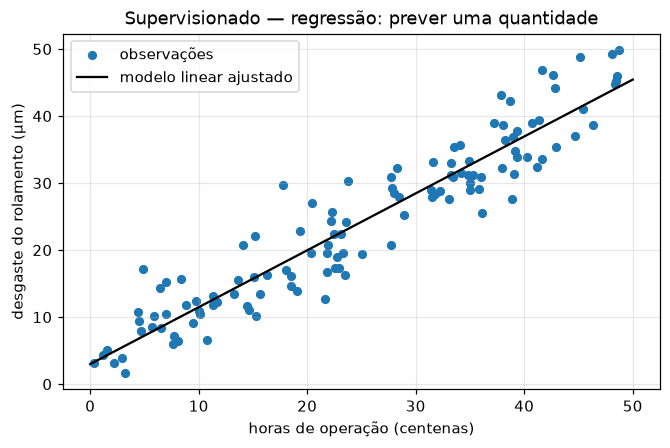

In [4]:
# horas de operação (centenas) -> desgaste do rolamento (µm), com ruído
horas = rng.uniform(0, 50, size=120)
desgaste = 3.0 + 0.85 * horas + rng.normal(0, 4.0, size=120)

A = np.column_stack([np.ones_like(horas), horas])       # matriz de projeto com coluna de 1s (viés)
beta, *_ = np.linalg.lstsq(A, desgaste, rcond=None)      # resolve min ||y - A beta||^2

print(f"beta = [b, w] = [{beta[0]:.3f}, {beta[1]:.3f}]   (processo real: b=3.0, w=0.85)")

grade = np.linspace(0, 50, 100)
plt.figure()
plt.scatter(horas, desgaste, s=25, label="observações")
plt.plot(grade, beta[0] + beta[1] * grade, color="black", label="modelo linear ajustado")
plt.xlabel("horas de operação (centenas)")
plt.ylabel("desgaste do rolamento (µm)")
plt.title("Supervisionado — regressão: prever uma quantidade")
plt.legend()
plt.show()

Os coeficientes recuperados ficam próximos — mas não iguais — aos do processo gerador. A diferença vem do
ruído e do tamanho finito da amostra. Guarde essa observação: **estimativas têm incerteza**, e reportar um
coeficiente com quatro casas decimais sem discutir essa incerteza é um erro de método.

### 9.2 Supervisionado — classificação

Mesma estrutura $(\mathbf{x}_i, y_i)$, mas agora $y_i$ é um **rótulo** de um conjunto finito. Foi o caso do
limiar de vibração (duas classes). A saída não é um número em uma escala contínua; é uma decisão — e por
isso as métricas de avaliação serão completamente diferentes (seção 11).

### 9.3 Não supervisionado — agrupamento

Aqui **não há $y$**. Recebemos apenas $\mathbf{X}$ e queremos descobrir estrutura. No agrupamento, buscamos
partições dos dados que minimizem a dispersão interna:

$$\min_{\{\boldsymbol{\mu}_k\}} \sum_{i=1}^{n} \left\| \mathbf{x}_i - \boldsymbol{\mu}_{c_i} \right\|_2^2,$$

em que $\boldsymbol{\mu}_k$ é o centroide do grupo $k$ e $c_i$ é o grupo atribuído à observação $i$.
Compare com a seção 4.3: cada centroide é a **média** do seu grupo justamente porque o critério é
quadrático. O algoritmo k-means e suas limitações são o assunto da aula de 22/10; aqui ele aparece só para
tornar visível a diferença em relação ao caso supervisionado.

**Antes de executar a próxima célula:** os grupos encontrados sem rótulos vão coincidir com as três
"famílias" de motores que usei para gerar os dados? Registre sua hipótese e o motivo.

c:\Users\Carlos\miniconda3\envs\ibmec\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


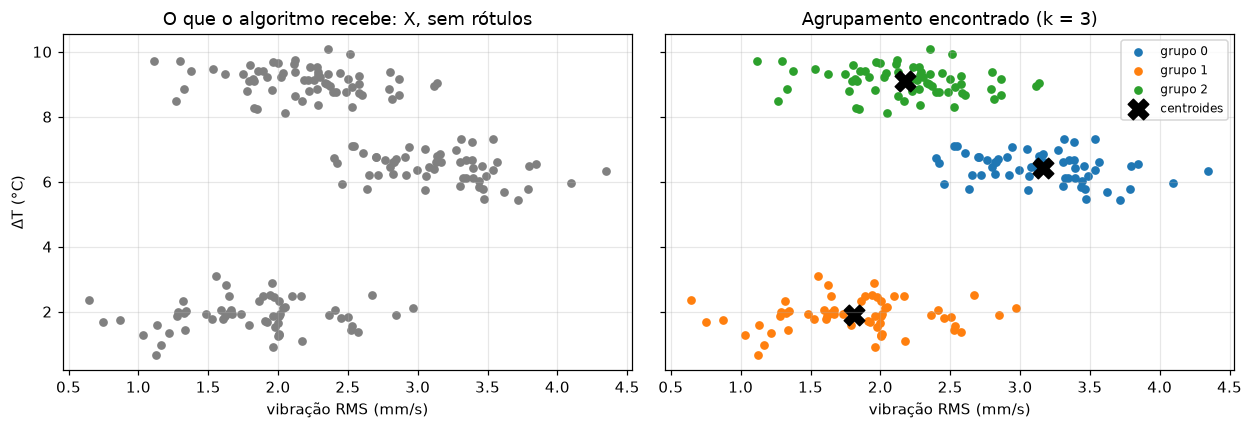

In [5]:
from sklearn.cluster import KMeans

# três regimes de operação: (vibração, temperatura acima da nominal)
centros_reais = np.array([[1.8, 2.0], [3.2, 6.5], [2.2, 9.0]])
grupos_reais = rng.integers(0, 3, size=180)
Xc = centros_reais[grupos_reais] + rng.normal(0, 0.45, size=(180, 2))

km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xc)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0), sharex=True, sharey=True)
ax1.scatter(Xc[:, 0], Xc[:, 1], s=22, color="gray")
ax1.set_title("O que o algoritmo recebe: X, sem rótulos")
ax1.set_xlabel("vibração RMS (mm/s)"); ax1.set_ylabel("ΔT (°C)")

for k in range(3):
    sel = km.labels_ == k
    ax2.scatter(Xc[sel, 0], Xc[sel, 1], s=22, label=f"grupo {k}")
ax2.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            marker="X", s=180, color="black", label="centroides")
ax2.set_title("Agrupamento encontrado (k = 3)")
ax2.set_xlabel("vibração RMS (mm/s)")
ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

### O que acabamos de observar?

Os grupos encontrados se parecem com os regimes que geraram os dados — mas há três ressalvas essenciais:

1. **Os rótulos dos grupos são arbitrários.** O "grupo 0" do k-means não corresponde ao "regime 0" do
   gerador; é apenas um índice. Não existe correspondência garantida.
2. **Precisamos informar $k = 3$.** O algoritmo não descobriu que havia três regimes: nós dissemos.
   Escolher $k$ sem rótulos é um problema em aberto que discutiremos na aula de 22/10.
3. **Não há como "acertar" ou "errar" no sentido supervisionado.** Sem $y$, não existe erro de
   classificação; existe apenas um critério interno (a soma de distâncias quadráticas) que pode ser
   minimizado por partições que não correspondem a nada de interesse prático.

Essa é a diferença fundamental entre os dois paradigmas: no supervisionado há uma resposta contra a qual
comparar; no não supervisionado, a validação depende de interpretação e de conhecimento do domínio.

### 9.4 Não supervisionado — redução de dimensionalidade

O outro grande grupo de métodos não supervisionados busca **representações mais compactas**. A Análise de
Componentes Principais (PCA, aula de 22/10) procura direções ortogonais que preservam o máximo de
variância. Uma demonstração mínima com os mesmos dados:

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(Xc)
print("variância explicada por componente:", np.round(pca.explained_variance_ratio_, 4))
print("acumulada:", np.round(np.cumsum(pca.explained_variance_ratio_), 4))
print("\nDireção da 1ª componente principal:", np.round(pca.components_[0], 3))
print("Ou seja: uma única coordenada já retém "
      f"{pca.explained_variance_ratio_[0]:.1%} da variância dos dois atributos originais.")

variância explicada por componente: [0.9511 0.0489]
acumulada: [0.9511 1.    ]

Direção da 1ª componente principal: [0.072 0.997]
Ou seja: uma única coordenada já retém 95.1% da variância dos dois atributos originais.


### 9.5 Aprendizado por reforço

Aqui não há um conjunto de dados fixo. Um **agente** escolhe **ações**, o **ambiente** responde com uma
**recompensa** e um novo estado, e o objetivo é maximizar a recompensa acumulada ao longo do tempo. A
dificuldade característica é o **dilema exploração–explotação**: usar a melhor ação conhecida ou testar
outra que talvez seja melhor?

Um caso mínimo: três estratégias de manutenção (ações), cada uma com uma taxa de sucesso desconhecida.
A cada dia escolhemos uma e observamos sucesso (1) ou falha (0). Usamos a política $\varepsilon$-gulosa:
com probabilidade $\varepsilon$ escolhemos uma ação ao acaso (exploração), caso contrário a de maior média
estimada (explotação). Este é o problema do *multi-armed bandit* — a porta de entrada do RL, que não é
conteúdo desta disciplina, mas cuja lógica você deve reconhecer.

taxas reais    : [0.3, 0.55, 0.45]
taxas estimadas: [0.364 0.55  0.34 ]
vezes escolhida: [  44 1406   50]
recompensa média final: 0.537  (ótimo teórico: 0.550)


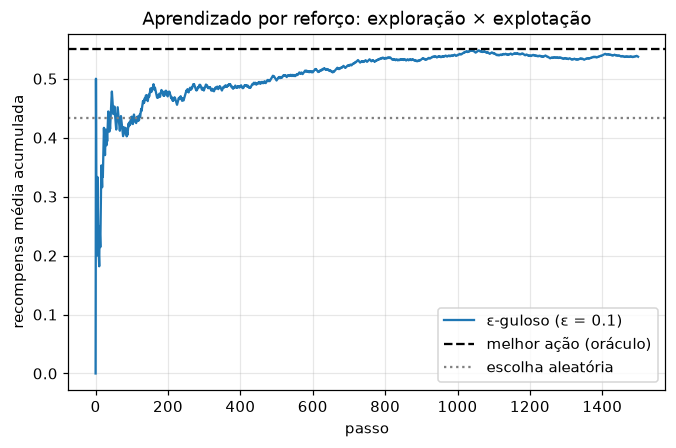

In [7]:
def bandit_epsilon_guloso(probs_reais, n_passos=1500, epsilon=0.1, seed=SEED):
    """Política ε-gulosa. Devolve (recompensas por passo, médias estimadas, contagens)."""
    r = np.random.default_rng(seed)
    n_acoes = len(probs_reais)
    somas = np.zeros(n_acoes)          # soma de recompensas por ação
    contagens = np.zeros(n_acoes)      # nº de vezes que cada ação foi escolhida
    recompensas = np.zeros(n_passos)

    for t in range(n_passos):
        if r.random() < epsilon or contagens.min() == 0:
            acao = r.integers(n_acoes)                       # explorar
        else:
            acao = int(np.argmax(somas / contagens))         # explotar
        recompensa = float(r.random() < probs_reais[acao])   # ambiente responde
        somas[acao] += recompensa
        contagens[acao] += 1
        recompensas[t] = recompensa

    return recompensas, somas / np.maximum(contagens, 1), contagens


probs_reais = [0.30, 0.55, 0.45]
recompensas, estimativas, contagens = bandit_epsilon_guloso(probs_reais)

print("taxas reais    :", probs_reais)
print("taxas estimadas:", np.round(estimativas, 3))
print("vezes escolhida:", contagens.astype(int))
print(f"recompensa média final: {recompensas.mean():.3f}  (ótimo teórico: {max(probs_reais):.3f})")

plt.figure()
plt.plot(np.cumsum(recompensas) / np.arange(1, len(recompensas) + 1), label="ε-guloso (ε = 0.1)")
plt.axhline(max(probs_reais), linestyle="--", color="black", label="melhor ação (oráculo)")
plt.axhline(np.mean(probs_reais), linestyle=":", color="gray", label="escolha aleatória")
plt.xlabel("passo"); plt.ylabel("recompensa média acumulada")
plt.title("Aprendizado por reforço: exploração × explotação")
plt.legend(); plt.show()

### O que acabamos de observar?

A curva sobe e se estabiliza **abaixo** do oráculo. Isso não é defeito de implementação: com
$\varepsilon = 0{,}1$, o agente gasta permanentemente 10% dos passos testando ações que já sabe serem
piores. O teto teórico é aproximadamente $(1-\varepsilon)\cdot 0{,}55 + \varepsilon \cdot \bar{p}$.

Note também que a ação **não é rotulada como certa ou errada** — apenas recebe uma recompensa ruidosa,
e a mesma ação pode devolver 0 em um passo e 1 no seguinte. É por isso que RL não se reduz a
aprendizado supervisionado.

## Exercício 4 — Classificando problemas na taxonomia

**Objetivo:** transferir a taxonomia para situações que você não viu implementadas.

**Tarefa:** para **cada** situação abaixo, indique o paradigma (supervisionado — regressão ou
classificação; não supervisionado — agrupamento ou redução de dimensionalidade; por reforço) e escreva,
explicitamente: o que é $\mathbf{x}_i$, o que é $y_i$ (se existir), qual seria a saída do sistema e qual
seria uma dificuldade prática de obter os dados necessários.

1. Prever o consumo de energia de um data center na próxima hora a partir de temperatura, carga de CPU e horário.
2. Detectar, em uma rede corporativa, máquinas cujo padrão de tráfego difere do restante da frota, sem lista prévia de máquinas comprometidas.
3. Decidir a política de escalonamento de tarefas de um sistema embarcado para minimizar consumo, testando decisões e observando a bateria ao longo de semanas.
4. Classificar e-mails em *spam* / não-*spam* a partir de uma base histórica marcada por usuários.
5. Comprimir vetores de 512 características extraídas de imagens de placas de circuito para 20 dimensões, de modo a acelerar uma busca por similaridade.
6. Estimar o tempo restante de vida útil de um SSD a partir de contadores S.M.A.R.T.

**Entregável:** uma tabela em Markdown com as seis situações e as quatro colunas pedidas.

> **Resposta:**
>
> | # | paradigma | $\mathbf{x}_i$ | $y_i$ | saída | dificuldade de obtenção dos dados |
> |---|---|---|---|---|---|
> | 1 | supervisionado — **regressão** | temperatura (°C), carga de CPU (%), hora do dia (cíclica: seno/cosseno), dia da semana | consumo de energia na hora seguinte (kWh) — contínuo | um número em kWh, atualizado a cada hora | exige **séries temporais alinhadas**: os atributos precisam ser os de *agora* e o rótulo o consumo de *daqui a uma hora*, o que obriga a deslocar o alvo no tempo. Erro clássico: usar a temperatura da hora prevista, que ainda não é conhecida (vazamento temporal). A validação também não pode ser aleatória — tem de respeitar a ordem cronológica |
> | 2 | não supervisionado — **agrupamento** / detecção de anomalias | vetor de tráfego por máquina: bytes enviados/recebidos, nº de conexões distintas, portas usadas, razão dia/noite, entropia dos destinos | **não existe** | lista de máquinas marcadas como atípicas, ordenadas por grau de desvio | não há rótulos por definição ("sem lista prévia de comprometidas"), então **não há como medir acurácia**; a validação depende de investigação manual pela equipe de segurança. Além disso, "diferente" ≠ "comprometida": o servidor de backup é legitimamente atípico. Exige também definir a janela de tempo e normalizar por porte da máquina |
> | 3 | **por reforço** | estado do sistema: nível de bateria, fila de tarefas, temperatura, frequência atual do processador | não é um rótulo: é uma **recompensa** escalar e atrasada (ex.: −consumo por intervalo, com penalidade por prazo perdido) | uma **política**: qual decisão de escalonamento tomar em cada estado | o retorno é **atrasado** (a decisão de hoje afeta a bateria de semanas depois) e obtido apenas por **interação real** — cada semana de experimento é uma amostra. Explorar políticas ruins em hardware de produção tem custo real, o que normalmente força o uso de um simulador, que por sua vez pode não corresponder ao mundo |
> | 4 | supervisionado — **classificação** (binária) | representação do texto e dos metadados: contagens/TF-IDF de termos, remetente, cabeçalhos, presença de links e anexos | rótulo $\in\{\text{spam}, \text{não-spam}\}$ | decisão binária por mensagem (idealmente com a probabilidade associada, para ajustar o limiar ao custo — Exercício 1) | os rótulos vêm de **usuários**, e portanto são ruidosos e enviesados (muita gente não marca spam; alguns marcam newsletters legítimas). Classes desbalanceadas, **privacidade** do conteúdo dos e-mails, e forte *concept drift*: quem envia spam muda de tática, então o modelo envelhece em semanas |
> | 5 | não supervisionado — **redução de dimensionalidade** | vetor de 512 características extraídas de cada imagem de placa | **não existe** | um vetor de 20 dimensões por imagem (a representação comprimida) usada para busca por similaridade | não precisa de rótulos, mas precisa de um **critério de sucesso** que não é óbvio: variância explicada não garante que a busca continue recuperando as placas certas. Exige um conjunto de pares "semelhante/não semelhante" para validar de fato, e a transformação deve ser ajustada **só no conjunto de referência** e depois aplicada às novas imagens |
> | 6 | supervisionado — **regressão** (vida útil restante) | contadores S.M.A.R.T.: blocos realocados, ciclos de liga/desliga, horas ligado, taxa de erros de leitura, temperatura, TBW | tempo restante até a falha (horas ou TB escritos) | estimativa de vida útil restante, para agendar a troca preventiva | é preciso esperar os discos **falharem** para conhecer o rótulo: os dados levam anos e só existem para as unidades que já morreram. Os discos ainda vivos são dados **censurados** (sabe-se apenas que a vida é maior que $t$) — descartá-los enviesa a amostra para os discos ruins. Também é raro: a maioria dos SSDs nunca falha na janela observada |
>
> **Padrão que se repete nas seis situações:** o que define o paradigma não é o algoritmo nem o domínio, e sim **o que existe como sinal de retorno** — um rótulo por exemplo (supervisionado), nenhum (não supervisionado) ou uma recompensa atrasada obtida por interação (reforço). E, nos quatro casos supervisionados, a dificuldade dominante não é modelar: é **conseguir o rótulo no tempo certo**.

## Exercício 5 — Exploração × explotação (investigação)

**Objetivo:** estabelecer experimentalmente a relação entre um hiperparâmetro e o comportamento do sistema.

**Tarefa:**
1. **Formule uma hipótese**, por escrito, sobre o efeito de $\varepsilon$ na recompensa média acumulada
   após 1500 passos, considerando os valores $\varepsilon \in \{0{,}0;\ 0{,}01;\ 0{,}05;\ 0{,}1;\ 0{,}3;\ 1{,}0\}$.
   Diga qual valor você espera ser o melhor e por quê.
2. Execute o experimento **repetindo cada configuração com 30 sementes diferentes** e registre a média e o
   desvio-padrão da recompensa média final.
3. Faça um gráfico da recompensa média final em função de $\varepsilon$, com barras de erro.
4. Explique o comportamento nos dois extremos ($\varepsilon = 0$ e $\varepsilon = 1$). Em particular:
   por que $\varepsilon = 0$ pode ter desempenho ruim **e** alta variância entre sementes?
5. Sua hipótese se sustentou? Se não, o que a corrigiu?

**Entregável:** a hipótese registrada **antes** dos resultados, o código, o gráfico com barras de erro e a
análise final.

> Dica: a função `bandit_epsilon_guloso` já aceita `epsilon` e `seed`. A condição
> `contagens.min() == 0` garante que toda ação seja testada ao menos uma vez — reflita sobre o efeito
> disso no caso $\varepsilon = 0$.

> **Hipótese (preencha ANTES de executar):**
>
> Espero uma curva em **U invertido**, com o melhor desempenho em um $\varepsilon$ pequeno mas não nulo — meu palpite é $\varepsilon = 0{,}05$ ou $\varepsilon = 0{,}1$.
>
> **Raciocínio.** Há dois efeitos em sentidos opostos:
>
> - **explorar demais custa.** Uma fração $\varepsilon$ dos 1500 passos é gasta em ações escolhidas ao acaso, cuja recompensa média é $\bar p = 0{,}433$ em vez de $0{,}55$. O teto teórico é $(1-\varepsilon)\cdot 0{,}55 + \varepsilon\cdot\bar p$, que **decresce** linearmente com $\varepsilon$ — em $\varepsilon = 1$ o agente vira uma escolha aleatória pura e deve ficar em $\approx 0{,}433$;
> - **explorar de menos também custa.** Com $\varepsilon = 0$, depois da rodada inicial obrigatória (a condição `contagens.min() == 0` força uma amostra de cada ação) o agente fixa-se para sempre na ação que tiver a maior média **estimada a partir de uma única observação**. Uma amostra de uma Bernoulli é um estimador péssimo: é bem provável que a ação de $p=0{,}45$ ou até a de $p=0{,}30$ tire um 1 na primeira tentativa enquanto a melhor tira um 0. Nesse caso ele trava na ação errada e **nunca mais corrige**, porque não volta a testar.
>
> Como o segundo efeito é catastrófico e o primeiro é gradual, espero que $\varepsilon = 0$ seja pior que $\varepsilon = 0{,}1$ **na média** e, principalmente, que tenha o **maior desvio-padrão entre sementes**: em algumas execuções ele acerta a melhor ação de cara e chega perto de 0,55; em outras trava em 0,30. Já $\varepsilon = 1{,}0$ deve ter média baixa mas variância pequena, porque não depende de sorte nenhuma — ele sempre sorteia uniformemente.
>
> **Previsão numérica:** $\varepsilon = 0$: média $\approx 0{,}45$ com desvio alto ($> 0{,}07$); $\varepsilon = 0{,}1$: média $\approx 0{,}52$; $\varepsilon = 1{,}0$: média $\approx 0{,}43$ com desvio baixo.

In [ ]:
# Exercício 5 — efeito de epsilon sobre a recompensa média, com 30 sementes por configuração.
epsilons = [0.0, 0.01, 0.05, 0.10, 0.30, 1.0]
N_SEMENTES = 30

medias, desvios, resultados = [], [], {}
for eps in epsilons:
    finais = np.array([
        bandit_epsilon_guloso(probs_reais, n_passos=1500, epsilon=eps, seed=s)[0].mean()
        for s in range(N_SEMENTES)
    ])
    resultados[eps] = finais
    medias.append(finais.mean())
    desvios.append(finais.std())

p_media = float(np.mean(probs_reais))
print(f"{'eps':>5} | {'média':>7} | {'desvio':>7} | {'mín':>7} | {'máx':>7} | {'teto teórico':>12}")
print("-" * 62)
for eps, m, d in zip(epsilons, medias, desvios):
    teto = (1 - eps) * max(probs_reais) + eps * p_media
    f = resultados[eps]
    print(f"{eps:5.2f} | {m:7.4f} | {d:7.4f} | {f.min():7.4f} | {f.max():7.4f} | {teto:12.4f}")

# Diagnóstico do caso eps = 0: em quantas sementes o agente travou na ação errada?
travadas = 0
for s in range(N_SEMENTES):
    _, _, contagens = bandit_epsilon_guloso(probs_reais, epsilon=0.0, seed=s)
    if int(np.argmax(contagens)) != int(np.argmax(probs_reais)):
        travadas += 1
print(f"\neps = 0: em {travadas} das {N_SEMENTES} sementes o agente passou a maior parte dos passos "
      f"numa ação SUBÓTIMA (e nunca mais testou as outras).")

# 3) gráfico com barras de erro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.errorbar(range(len(epsilons)), medias, yerr=desvios, fmt="o-", capsize=5, lw=1.8)
ax1.axhline(max(probs_reais), ls="--", color="black", label="melhor ação (oráculo) = 0.55")
ax1.axhline(p_media, ls=":", color="gray", label=f"escolha aleatória = {p_media:.3f}")
ax1.set_xticks(range(len(epsilons))); ax1.set_xticklabels([str(e) for e in epsilons])
ax1.set_xlabel("ε"); ax1.set_ylabel("recompensa média final (1500 passos)")
ax1.set_title(f"Média ± desvio sobre {N_SEMENTES} sementes")
ax1.legend(fontsize=8)

# a dispersão entre sementes é parte do resultado, não ruído a esconder
ax2.boxplot([resultados[e] for e in epsilons], tick_labels=[str(e) for e in epsilons])
ax2.axhline(max(probs_reais), ls="--", color="black")
ax2.set_xlabel("ε"); ax2.set_ylabel("recompensa média final")
ax2.set_title("Distribuição entre sementes (note a cauda de ε = 0)")

plt.tight_layout(); plt.show()

> **Análise do Exercício 5:**

**Resultados (30 sementes por configuração, 1500 passos cada):**

| $\varepsilon$ | média | desvio | mínimo | máximo | teto teórico |
|--:|--:|--:|--:|--:|--:|
| 0,00 | 0,4740 | **0,0937** | 0,2780 | 0,5687 | 0,5500 |
| 0,01 | 0,5044 | 0,0613 | 0,3047 | 0,5720 | 0,5488 |
| 0,05 | 0,5193 | 0,0436 | 0,4173 | 0,5580 | 0,5442 |
| **0,10** | **0,5250** | 0,0212 | 0,4647 | 0,5647 | 0,5383 |
| 0,30 | 0,5110 | 0,0184 | 0,4527 | 0,5607 | 0,5150 |
| 1,00 | 0,4281 | **0,0117** | 0,3980 | 0,4460 | 0,4333 |

**4. Os dois extremos.**

**$\varepsilon = 1{,}0$ — só exploração.** O agente ignora completamente o que aprendeu e sorteia uniformemente entre as três ações. A recompensa média converge para $\bar p = (0{,}30+0{,}55+0{,}45)/3 = 0{,}4333$, e foi isso que medimos (0,4281). O aprendizado acontece — as estimativas das três taxas ficam ótimas, porque todas são amostradas 500 vezes — mas **não é usado**. O desvio entre sementes é o menor de todos (0,0117) justamente porque o resultado não depende de sorte: é a média de 1500 Bernoullis com probabilidade fixa.

**$\varepsilon = 0$ — só explotação: pior média *e* maior variância.** Este é o ponto central do exercício. A média (0,4740) é pior que a de $\varepsilon = 0{,}1$, mas o que assusta é o desvio de **0,0937** — oito vezes o de $\varepsilon = 1{,}0$ — com resultados indo de 0,278 a 0,569. A explicação está na linha `contagens.min() == 0`: ela força uma amostra de cada ação e, **a partir daí, o agente escolhe para sempre a que teve a maior média estimada com uma única observação**. Uma amostra de Bernoulli vale 0 ou 1, então a estimativa inicial é praticamente um sorteio: há chance considerável de a ação de $p = 0{,}30$ tirar 1 enquanto a de $p = 0{,}55$ tira 0. Como o agente nunca mais explora, o erro é **absorvente** — ele não tem como descobrir que se enganou, pois só recebe informação da ação que já escolheu. Medimos isso diretamente: em **14 das 30 sementes** o agente passou a maior parte dos 1500 passos numa ação subótima.

Essa é a assinatura do problema: quando o desempenho depende de uma decisão irreversível tomada com pouca informação, a média esconde uma distribuição **bimodal** (ou acerta e fica em ~0,55, ou trava e fica em ~0,30/0,45) — como o *boxplot* mostra. Reportar apenas "0,474" seria enganoso: nenhuma execução individual se parece com esse número.

**5. A hipótese se sustentou?** Sim, nas três previsões: o formato de U invertido, o ótimo em $\varepsilon = 0{,}1$ e o desvio máximo em $\varepsilon = 0$. Os valores previstos (0,45 / 0,52 / 0,43) ficaram próximos dos medidos (0,474 / 0,525 / 0,428). O que a hipótese **não** antecipou foi que $\varepsilon = 0{,}01$ e $\varepsilon = 0{,}05$ ficariam com desvios intermediários e altos (0,061 e 0,044): explorar pouco reduz a probabilidade de travar, mas não a elimina, porque leva muitos passos para acumular evidência suficiente para trocar de ação. E $\varepsilon = 0{,}3$ mostrou o outro lado: desvio pequeno (0,018) e média já em queda, pois 30% dos passos jogados fora superam o benefício de identificar a melhor ação.

**Conclusão transferível.** Nenhum $\varepsilon$ fixo atinge o teto teórico, porque o custo de explorar é permanente enquanto o benefício é decrescente — depois de mil passos já se sabe qual ação é a melhor, e continuar testando é desperdício. Por isso, na prática, usa-se $\varepsilon$ **decrescente** ($\varepsilon_t = \varepsilon_0/\sqrt{t}$) ou métodos que exploram de forma dirigida (UCB, amostragem de Thompson), que concentram a exploração nas ações cuja estimativa ainda é incerta em vez de sortear uniformemente. É a mesma lógica da taxa de aprendizagem decrescente que reaparece em otimização.

## 10. O pipeline de um projeto de Machine Learning

Modelar é a parte pequena de um projeto de ML. O que separa um resultado publicável de um número sem
sentido é o **processo**. As etapas abaixo serão repetidas, com variações, em todas as aulas seguintes:

```
 1. Definição do problema      → qual decisão será tomada? qual é o custo de errar?
 2. Obtenção dos dados         → quais variáveis existem NO MOMENTO da decisão?
 3. Análise exploratória       → distribuições, escalas, faltantes, balanceamento
 4. Separação treino/teste     → ANTES de qualquer transformação ajustada aos dados
 5. Baseline                   → o número mínimo que o modelo precisa superar
 6. Preparação dos dados       → limpeza, codificação, normalização (ajustadas só no treino)
 7. Treinamento                → escolha do modelo e minimização do risco empírico
 8. Avaliação                  → métricas adequadas ao problema, não a acurácia por hábito
 9. Análise de erros           → onde e por que o modelo erra
10. Implantação e monitoramento→ o mundo muda; o modelo envelhece
```

Duas etapas concentram a maior parte dos erros graves que vejo em projetos reais:

- a **etapa 4**, quando executada depois da 6 (isso é vazamento de dados — seção 11.2);
- a **etapa 2**, quando entra no conjunto de atributos alguma variável que **só existe depois** do evento
  que se quer prever (isso é vazamento temporal — a investigação final trata disso).

Vamos percorrer o pipeline inteiro com o problema da manutenção preditiva.

### 10.1 Definição do problema e obtenção dos dados

**Decisão:** para cada motor, ao final do turno, emitir ou não uma ordem de inspeção para o dia seguinte.
**Alvo:** `falha` = 1 se o motor apresentou falha de rolamento no dia seguinte.
**Atributos disponíveis no momento da decisão:** vibração RMS, temperatura do mancal, horas acumuladas de
operação e corrente elétrica média.

Novamente geramos os dados com um processo conhecido, para podermos auditar as conclusões.
Repare que `corrente_a` **não participa** da geração de `falha`: é uma variável irrelevante,
propositalmente incluída. Um bom procedimento deve ser capaz de conviver com ela.

In [8]:
def gerar_dados_motores(n=800, seed=SEED):
    """Base sintética de manutenção preditiva.

    Processo gerador:
        z = 1.4*(rms - 2.2) + 0.09*(temp - 62) + 0.00018*(horas - 4500) + ruído
        falha = 1 se z > 0.80
    A variável 'corrente_a' é gerada de forma independente e NÃO afeta a falha.
    """
    r = np.random.default_rng(seed)

    rms = r.normal(2.20, 0.50, n).clip(0.2, None)
    temp = r.normal(62.0, 6.0, n)
    horas = r.uniform(0, 9000, n)
    corrente = r.normal(11.0, 1.2, n)          # irrelevante por construção

    z = (1.40 * (rms - 2.20)
         + 0.09 * (temp - 62.0)
         + 0.00018 * (horas - 4500.0)
         + r.normal(0, 0.60, n))
    falha = (z > 0.80).astype(int)

    return pd.DataFrame({
        "rms_vibracao": rms.round(3),
        "temperatura": temp.round(2),
        "horas_operacao": horas.round(0),
        "corrente_a": corrente.round(3),
        "falha": falha,
    })


dados = gerar_dados_motores()
dados.head(8)

,rms_vibracao,temperatura,horas_operacao,corrente_a,falha
0,2.352,56.93,6791.0,8.647,0
1,1.680,55.50,880.0,11.847,0
2,2.575,64.07,4214.0,9.008,0
3,2.670,64.28,1805.0,11.371,0
4,1.224,69.72,1668.0,9.935,0
5,1.549,68.60,4174.0,9.608,0
6,2.264,61.21,2605.0,10.470,0
7,2.042,54.53,7165.0,10.780,0


### 10.2 Análise exploratória

Antes de qualquer modelo: olhar os dados. Três perguntas mínimas — há valores faltantes? qual é a **escala**
de cada atributo? como as classes estão **balanceadas**?

In [9]:
print("dimensões:", dados.shape)
print("\nvalores faltantes por coluna:")
print(dados.isna().sum())

print("\ndistribuição do alvo:")
print(dados["falha"].value_counts().rename({0: "sem falha", 1: "com falha"}))
print(f"prevalência de falhas: {dados['falha'].mean():.1%}")

print("\nestatísticas descritivas dos atributos:")
dados.drop(columns="falha").describe().round(2)

dimensões: (800, 5)

valores faltantes por coluna:
rms_vibracao      0
temperatura       0
horas_operacao    0
corrente_a        0
falha             0
dtype: int64

distribuição do alvo:
falha
sem falha    615
com falha    185
Name: count, dtype: int64
prevalência de falhas: 23.1%

estatísticas descritivas dos atributos:


,rms_vibracao,temperatura,horas_operacao,corrente_a
count,800.00,800.00,800.00,800.00
mean,2.19,61.76,4472.49,11.05
std,0.49,6.13,2626.64,1.20
min,0.72,40.11,5.00,7.57
25%,1.84,57.82,2224.00,10.20
50%,2.20,61.96,4414.50,11.01
75%,2.51,65.69,6805.00,11.90
max,3.66,81.07,8998.00,14.67


Observe as escalas: `horas_operacao` varia em milhares, `rms_vibracao` em unidades. Um método baseado em
**distância** (seção 4.2) somará $(\Delta \text{horas})^2$ com $(\Delta \text{rms})^2$ — e o primeiro
termo dominará completamente o segundo, não porque seja mais informativo, mas porque a unidade é maior.
Vamos medir esse efeito em vez de apenas afirmá-lo (seção 10.6).

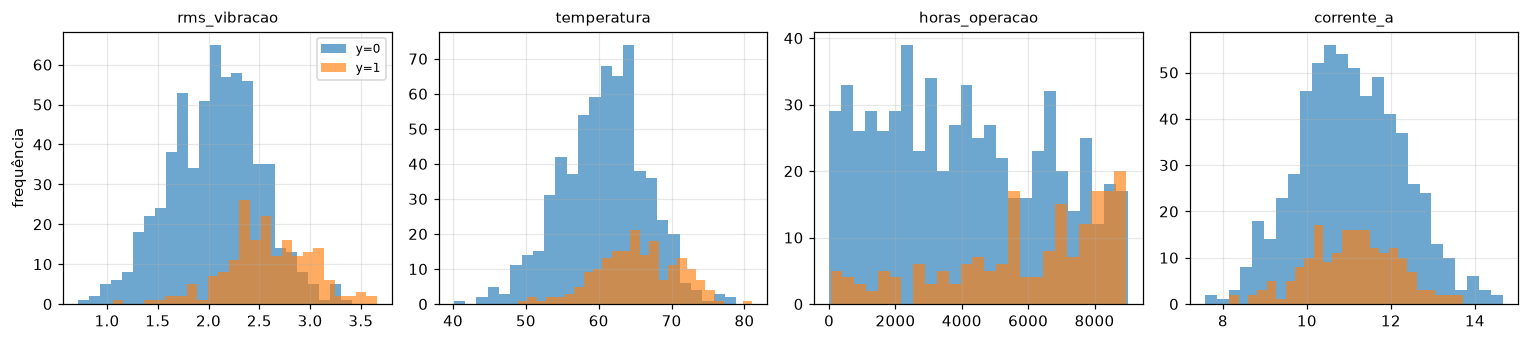

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, coluna in zip(axes, ["rms_vibracao", "temperatura", "horas_operacao", "corrente_a"]):
    ax.hist(dados.loc[dados.falha == 0, coluna], bins=25, alpha=0.65, label="y=0")
    ax.hist(dados.loc[dados.falha == 1, coluna], bins=25, alpha=0.65, label="y=1")
    ax.set_title(coluna, fontsize=10)
    ax.set_xlabel("")
axes[0].set_ylabel("frequência")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### O que acabamos de observar?

Nos três primeiros atributos as distribuições condicionais $P(x_j \mid y=0)$ e $P(x_j \mid y=1)$ estão
**deslocadas** uma em relação à outra — há informação sobre a classe. Em `corrente_a` elas praticamente
coincidem, como esperado: essa variável foi gerada independentemente do alvo.

Cuidado com a interpretação: sobreposição visual **não** significa ausência de informação. Um atributo
pode ser inútil isoladamente e valioso em combinação com outro (interação). O inverso também ocorre.
Gráficos univariados são um primeiro filtro, não um veredito.

### 10.3 Separação treino/teste — a etapa que não pode ser adiada

Se ajustarmos qualquer coisa (uma normalização, uma seleção de atributos, uma escolha de hiperparâmetro)
usando **todas** as observações e só depois separarmos o teste, o conjunto de teste já terá influenciado o
modelo. A estimativa de desempenho fica otimista — às vezes de forma dramática (seção 11.2).

Usamos `stratify=y` para preservar a proporção de falhas nos dois subconjuntos: sem isso, com classes
desbalanceadas, o acaso pode produzir um teste com proporção muito diferente da real.

In [11]:
from sklearn.model_selection import train_test_split

X = dados.drop(columns="falha")
y = dados["falha"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

print(f"treino: {X_treino.shape[0]} obs · prevalência {y_treino.mean():.3f}")
print(f"teste : {X_teste.shape[0]} obs · prevalência {y_teste.mean():.3f}")
print("\nA partir daqui, X_teste e y_teste NÃO serão usados para nenhuma decisão de modelagem.")

treino: 560 obs · prevalência 0.232
teste : 240 obs · prevalência 0.229

A partir daqui, X_teste e y_teste NÃO serão usados para nenhuma decisão de modelagem.


### 10.4 Baseline — o número que precisa ser superado

Nenhuma métrica significa alguma coisa isoladamente. 78% de acurácia é excelente ou desprezível? Depende
do que se obtém **sem modelo algum**. O `DummyClassifier` implementa estratégias triviais; a mais dura de
bater em problemas desbalanceados é sempre responder a classe majoritária.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
acc_baseline = accuracy_score(y_teste, baseline.predict(X_teste))

print(f"Baseline (sempre responder a classe majoritária): acurácia = {acc_baseline:.4f}")
print(f"Confira: 1 - prevalência de falhas no teste = {1 - y_teste.mean():.4f}")
print("\nQualquer modelo com acurácia próxima disso não está agregando informação alguma.")

Baseline (sempre responder a classe majoritária): acurácia = 0.7708
Confira: 1 - prevalência de falhas no teste = 0.7708

Qualquer modelo com acurácia próxima disso não está agregando informação alguma.


### 10.5 O modelo: um classificador por centroide, implementado do zero

Para não usar caixas-pretas em uma aula de fundamentos, vamos usar um modelo que podemos escrever
inteiro em cinco linhas de matemática.

**Ideia.** Calcule o centro de massa de cada classe no espaço de atributos. Classifique uma nova
observação pela classe cujo centro estiver **mais próximo**.

**Treinamento.** Para cada classe $k$, com $n_k$ observações de treino:

$$\boldsymbol{\mu}_k = \frac{1}{n_k}\sum_{i:\,y_i=k} \mathbf{x}_i \;\in\; \mathbb{R}^{p}.$$

Note que isso **é** o minimizador do erro quadrático dentro de cada classe (seção 4.3) — o treinamento tem
solução fechada, sem iteração.

**Previsão.**

$$\hat{y} = \arg\min_{k} \; \left\| \mathbf{x} - \boldsymbol{\mu}_k \right\|_2.$$

**Dimensões:** $\mathbf{X} \in \mathbb{R}^{n\times p}$, a matriz de centroides é
$\mathbb{R}^{K\times p}$, e a matriz de distâncias calculada na previsão é $\mathbb{R}^{n\times K}$.

**Custo computacional:** treino $O(np)$; inferência $O(nKp)$ — barato, adequado até a sistemas embarcados.

**Hipóteses implícitas** (importantes, e frequentemente falsas): classes aproximadamente esféricas, de
dispersão semelhante, e atributos em escalas comparáveis.

Implementamos seguindo a API do scikit-learn (`fit` / `predict`), o que permitirá reutilizar
`Pipeline`, `cross_val_score` e todo o restante do ecossistema.

In [13]:
from sklearn.base import BaseEstimator, ClassifierMixin


class ClassificadorPorCentroide(BaseEstimator, ClassifierMixin):
    """Atribui a cada observação a classe cujo centroide está mais próximo (distância euclidiana)."""

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        # centroides_: (K, p) -- uma linha por classe
        self.centroides_ = np.vstack([X[y == c].mean(axis=0) for c in self.classes_])
        self.n_features_in_ = X.shape[1]
        return self

    def _distancias(self, X):
        X = np.asarray(X, dtype=float)
        # (n,1,p) - (1,K,p) -> (n,K,p);  norma no eixo dos atributos -> (n,K)
        return np.linalg.norm(X[:, None, :] - self.centroides_[None, :, :], axis=2)

    def predict(self, X):
        return self.classes_[np.argmin(self._distancias(X), axis=1)]


# treinamento SEM normalização, para medir o efeito da escala
modelo_sem_escala = ClassificadorPorCentroide().fit(X_treino, y_treino)

print("centroides aprendidos (linhas = classes 0 e 1):")
print(pd.DataFrame(modelo_sem_escala.centroides_,
                   columns=X.columns, index=["classe 0", "classe 1"]).round(2))

acc_sem_escala = accuracy_score(y_teste, modelo_sem_escala.predict(X_teste))
print(f"\nacurácia no teste (sem normalização): {acc_sem_escala:.4f}")
print(f"baseline                            : {acc_baseline:.4f}")

centroides aprendidos (linhas = classes 0 e 1):
          rms_vibracao  temperatura  horas_operacao  corrente_a
classe 0          2.07        60.61         3973.27       11.04
classe 1          2.59        65.50         5844.95       11.15

acurácia no teste (sem normalização): 0.6250
baseline                            : 0.7708


### 10.6 Por que a normalização não é um detalhe

Olhe a tabela de centroides: as classes diferem em `horas_operacao` por algumas centenas de unidades e em
`rms_vibracao` por décimos. Na soma que define a distância euclidiana,

$$\|\mathbf{x}-\boldsymbol{\mu}_k\|_2^2 = \underbrace{(\Delta\text{rms})^2}_{\sim 10^{-1}}
+ \underbrace{(\Delta\text{temp})^2}_{\sim 10^{1}}
+ \underbrace{(\Delta\text{horas})^2}_{\sim 10^{6}}
+ \underbrace{(\Delta\text{corrente})^2}_{\sim 10^{0}},$$

o terceiro termo domina tudo. Na prática, o modelo está decidindo **quase só por horas de operação** —
e a variável mais informativa (vibração) é ignorada por acidente de unidade.

A **padronização** (z-score) corrige isso colocando cada atributo em média 0 e desvio 1:

$$x'_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}.$$

Ponto crítico: $\bar{x}_j$ e $s_j$ devem ser calculados **apenas no conjunto de treinamento** e depois
aplicados ao teste. Usar as estatísticas do conjunto completo é vazamento de dados. O objeto `Pipeline`
existe exatamente para tornar esse erro difícil de cometer: dentro dele, o `fit` do `StandardScaler`
acontece só sobre a partição de treino de cada divisão.

**Antes de executar a próxima célula:** de quanto você espera que a acurácia melhore com a padronização?
Registre um palpite numérico.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelo = Pipeline([
    ("escala", StandardScaler()),
    ("clf", ClassificadorPorCentroide()),
])
modelo.fit(X_treino, y_treino)

acc_com_escala = accuracy_score(y_teste, modelo.predict(X_teste))

print(f"baseline                  : {acc_baseline:.4f}")
print(f"sem normalização          : {acc_sem_escala:.4f}")
print(f"com normalização (Pipeline): {acc_com_escala:.4f}")

centroides_padronizados = modelo.named_steps["clf"].centroides_
print("\ncentroides no espaço padronizado (em desvios-padrão):")
print(pd.DataFrame(centroides_padronizados, columns=X.columns,
                   index=["classe 0", "classe 1"]).round(3))

baseline                  : 0.7708
sem normalização          : 0.6250
com normalização (Pipeline): 0.8125

centroides no espaço padronizado (em desvios-padrão):
          rms_vibracao  temperatura  horas_operacao  corrente_a
classe 0        -0.249       -0.184          -0.168      -0.021
classe 1         0.825        0.607           0.555       0.069


### O que acabamos de observar?

A tabela de centroides padronizados agora é **legível**: cada número está em desvios-padrão, então as
diferenças entre classes são comparáveis entre atributos. Verifique que a separação é grande em
`rms_vibracao` e `temperatura`, moderada em `horas_operacao` e praticamente nula em `corrente_a` —
exatamente a estrutura do processo gerador, recuperada a partir dos dados.

Duas lições de método:

1. **Uma transformação de pré-processamento pode valer mais que uma troca de modelo.** Antes de partir para
   um algoritmo mais sofisticado, verifique se o atual está sendo alimentado corretamente.
2. **O modelo não "descobriu" que corrente é irrelevante.** Ele continua usando essa dimensão na distância;
   apenas os centroides quase coincidem nela, de modo que a contribuição é pequena e ruidosa. Seleção de
   atributos é um problema por si só (aula de 15/10).

### 10.7 Avaliação: acurácia é insuficiente

Para classificação binária, o resumo completo das decisões é a **matriz de confusão**:

| | previsto 0 | previsto 1 |
|---|---|---|
| **real 0** | VN (verdadeiro negativo) | FP (falso positivo) |
| **real 1** | FN (falso negativo) | VP (verdadeiro positivo) |

A partir dela:

$$\text{acurácia}=\frac{VP+VN}{VP+VN+FP+FN}, \qquad
\text{precisão}=\frac{VP}{VP+FP}, \qquad
\text{recall}=\frac{VP}{VP+FN},$$

$$F_1 = 2\cdot\frac{\text{precisão}\cdot\text{recall}}{\text{precisão}+\text{recall}}.$$

Em português de engenharia: **recall** é a fração de motores que iam falhar e que conseguimos avisar;
**precisão** é a fração dos alarmes emitidos que eram justificados. O Exercício 1 já mostrou que essas
duas quantidades têm custos diferentes — e elas se opõem: é trivial obter recall 1,0 alarmando todo mundo.
O estudo aprofundado dessas métricas, incluindo curva ROC e AUC, é a aula de 17/09.

In [15]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = modelo.predict(X_teste)
mc = confusion_matrix(y_teste, y_pred)

print("matriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(mc, index=["real 0", "real 1"], columns=["prev 0", "prev 1"]))

vn, fp, fn, vp = mc.ravel()
print(f"\nVN={vn}  FP={fp}  FN={fn}  VP={vp}")
print(f"acurácia = {(vp+vn)/mc.sum():.4f}")
print(f"precisão = {vp/(vp+fp):.4f}")
print(f"recall   = {vp/(vp+fn):.4f}")

print("\n", classification_report(y_teste, y_pred, target_names=["sem falha", "com falha"]))

matriz de confusão (linhas = real, colunas = previsto):
        prev 0  prev 1
real 0     147      38
real 1       7      48

VN=147  FP=38  FN=7  VP=48
acurácia = 0.8125
precisão = 0.5581
recall   = 0.8727

               precision    recall  f1-score   support

   sem falha       0.95      0.79      0.87       185
   com falha       0.56      0.87      0.68        55

    accuracy                           0.81       240
   macro avg       0.76      0.83      0.77       240
weighted avg       0.86      0.81      0.82       240



### 10.8 Validação cruzada

A acurácia acima foi medida em **uma** partição de teste com poucas centenas de observações. Trocando a
semente, o número muda. A **validação cruzada em $k$ dobras** reduz essa dependência: os dados de treino são
divididos em $k$ partes; treina-se em $k-1$ e avalia-se na restante, repetindo $k$ vezes. Obtemos $k$
estimativas — e portanto uma **média e uma dispersão**.

Repare que passamos o `Pipeline` inteiro para `cross_val_score`, e não os dados já normalizados: assim o
`StandardScaler` é reajustado dentro de cada dobra, sem ver a parte usada para validação.
Detalhe fundamental: a validação cruzada é feita **sobre o treino**. O conjunto de teste continua intocado.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="accuracy")

print("acurácia por dobra:", np.round(scores, 4))
print(f"média = {scores.mean():.4f}   desvio-padrão = {scores.std():.4f}")
print(f"\nReporte assim: {scores.mean():.3f} ± {scores.std():.3f}, e não um número isolado.")

acurácia por dobra: [0.7857 0.9018 0.8036 0.8482 0.7589]
média = 0.8196   desvio-padrão = 0.0503

Reporte assim: 0.820 ± 0.050, e não um número isolado.


## Exercício 6 — Separação treino/teste implementada do zero

**Objetivo:** entender o que `train_test_split(..., stratify=y)` faz por dentro.

**Tarefa:** implemente `dividir_estratificado(X, y, teste=0.3, seed=0)` usando apenas NumPy, devolvendo
`X_treino, X_teste, y_treino, y_teste`. A função deve, para **cada classe** separadamente, embaralhar os
índices e enviar a fração `teste` para o conjunto de teste.
1. Verifique que a prevalência de falhas é preservada nas duas partições (tolerância de 1 ponto percentual).
2. Compare, para cinco sementes, a prevalência obtida pela sua função **estratificada** com a de uma divisão
   puramente aleatória (sem estratificação). Qual delas varia mais?
3. Explique em que cenário a ausência de estratificação seria realmente danosa. *Dica: pense em uma classe
   com prevalência de 2%.*

**Entregável:** a implementação, a tabela comparativa das cinco sementes e a discussão.

In [ ]:
# Exercício 6 — o que train_test_split(..., stratify=y) faz por dentro.

def dividir_estratificado(X, y, teste=0.3, seed=0):
    """Divide preservando a proporção de cada classe nas duas partições."""
    r = np.random.default_rng(seed)
    Xa, ya = np.asarray(X), np.asarray(y)

    indices_teste = []
    for classe in np.unique(ya):                       # cada classe é sorteada separadamente
        idx_c = r.permutation(np.flatnonzero(ya == classe))
        n_teste_c = int(round(teste * len(idx_c)))     # mesma fração dentro da classe
        indices_teste.append(idx_c[:n_teste_c])
    indices_teste = np.concatenate(indices_teste)

    e_teste = np.zeros(len(ya), dtype=bool)
    e_teste[indices_teste] = True
    return Xa[~e_teste], Xa[e_teste], ya[~e_teste], ya[e_teste]


def dividir_aleatorio(X, y, teste=0.3, seed=0):
    """Mesma divisão, SEM estratificação — para servir de comparação."""
    r = np.random.default_rng(seed)
    Xa, ya = np.asarray(X), np.asarray(y)
    idx = r.permutation(len(ya))
    n_teste = int(round(teste * len(ya)))
    te, tr = idx[:n_teste], idx[n_teste:]
    return Xa[tr], Xa[te], ya[tr], ya[te]


X_np, y_np = np.asarray(X), np.asarray(y)
prevalencia = y_np.mean()
print(f"prevalência de falhas na base completa: {prevalencia:.4f}\n")

# 1) e 2) cinco sementes, estratificado x aleatório
print(f"{'seed':>4} | {'estrat. treino':>14} | {'estrat. teste':>13} | {'aleat. treino':>13} | {'aleat. teste':>12}")
print("-" * 70)
prev_estrat, prev_aleat = [], []
for s in range(5):
    _, _, ytr_e, yte_e = dividir_estratificado(X_np, y_np, teste=0.3, seed=s)
    _, _, ytr_a, yte_a = dividir_aleatorio(X_np, y_np, teste=0.3, seed=s)
    prev_estrat.append(yte_e.mean()); prev_aleat.append(yte_a.mean())
    assert abs(yte_e.mean() - prevalencia) < 0.01, "estratificação falhou (tolerância de 1 p.p.)"
    print(f"{s:4d} | {ytr_e.mean():14.4f} | {yte_e.mean():13.4f} | {ytr_a.mean():13.4f} | {yte_a.mean():12.4f}")

print(f"\ndesvio da prevalência no teste — estratificado: {np.std(prev_estrat):.5f}"
      f" | aleatório: {np.std(prev_aleat):.5f}")
print(f"amplitude (máx - mín)          — estratificado: {max(prev_estrat) - min(prev_estrat):.5f}"
      f" | aleatório: {max(prev_aleat) - min(prev_aleat):.5f}")
print("Todas as sementes estratificadas dão a MESMA prevalência: ela é imposta, não sorteada.")

# 3) por que isso importa de verdade: classe com prevalência de ~2%
r_raro = np.random.default_rng(1)
y_raro_dem = (r_raro.random(300) < 0.02).astype(int)
X_raro_dem = np.zeros((300, 1))
print(f"\nCenário raro: n = 300, {y_raro_dem.sum()} positivos ({y_raro_dem.mean():.1%})")

pos_estrat, pos_aleat = [], []
for s in range(200):
    _, _, _, yte_e = dividir_estratificado(X_raro_dem, y_raro_dem, teste=0.3, seed=s)
    _, _, _, yte_a = dividir_aleatorio(X_raro_dem, y_raro_dem, teste=0.3, seed=s)
    pos_estrat.append(int(yte_e.sum())); pos_aleat.append(int(yte_a.sum()))

print(f"  positivos no teste — estratificado: mín {min(pos_estrat)}, máx {max(pos_estrat)}")
print(f"  positivos no teste — aleatório    : mín {min(pos_aleat)}, máx {max(pos_aleat)}")
print(f"  divisões aleatórias com ZERO positivos no teste: "
      f"{sum(1 for v in pos_aleat if v == 0)} de 200 ({sum(1 for v in pos_aleat if v == 0) / 2:.1f}%)")
print("  -> nessas divisões, recall e precisão são indefinidos: o teste não contém a classe de interesse.")

> **Discussão do Exercício 6:**

**1. e 2. A comparação nas cinco sementes** (prevalência real: 0,2313):

| semente | estratificado (treino / teste) | aleatório (treino / teste) |
|--:|:--|:--|
| 0 | 0,2304 / 0,2333 | 0,2411 / 0,2083 |
| 1 | 0,2304 / 0,2333 | 0,2375 / 0,2167 |
| 2 | 0,2304 / 0,2333 | 0,2196 / 0,2583 |
| 3 | 0,2304 / 0,2333 | 0,2304 / 0,2333 |
| 4 | 0,2304 / 0,2333 | 0,2429 / 0,2042 |
| **desvio** | **0,00000** | **0,01979** |
| **amplitude** | **0,00000** | **0,05417** |

A versão aleatória varia mais — e o resultado estratificado tem uma propriedade mais forte do que "varia pouco": ele é **idêntico em todas as sementes**. Isso não é coincidência. A estratificação sorteia *quais* observações vão para cada partição, mas o **número** de observações de cada classe é calculado deterministicamente (`round(0,3 × n_c)`); só a composição muda, nunca a proporção. A prevalência deixa de ser uma variável aleatória e passa a ser uma restrição do procedimento.

Já a divisão puramente aleatória faz a contagem de positivos no teste seguir uma distribuição **hipergeométrica**, com desvio-padrão de aproximadamente $\sqrt{n_{te}\,p(1-p)}/n_{te} = \sqrt{0{,}231 \cdot 0{,}769/240} \approx 0{,}027$ — a mesma ordem de grandeza dos 0,0198 medidos. A amplitude observada foi de **5,4 pontos percentuais** entre a melhor e a pior semente, só na composição do teste.

**3. Quando a ausência de estratificação é realmente danosa.** Com 23% de prevalência o estrago é moderado: uma variação de 5 p.p. na composição do teste desloca a acurácia do *baseline* e torna as comparações entre execuções menos confiáveis, mas nenhuma métrica quebra. O quadro muda com **classes raras**. Simulando o caso citado na dica (prevalência de ~2%, $n = 300$, apenas 5 positivos):

- estratificado: **sempre 2 positivos** no teste, em todas as 200 divisões;
- aleatório: de **0 a 4** positivos — e em **41 das 200 divisões (20,5%) o conjunto de teste não contém nenhum positivo**.

Nessas 41 divisões o resultado é inutilizável: recall é $0/0$ (indefinido), a matriz de confusão tem uma linha vazia, `classification_report` emite aviso e devolve 0, e a acurácia é 100% para qualquer modelo que nunca alarme. Um relatório produzido com uma dessas divisões pareceria perfeito e não significaria nada. Pior: se o programa não quebrar, ninguém percebe.

**Onde isso aparece na prática:** detecção de fraude (0,1%–1%), diagnóstico de doenças raras, falhas catastróficas de equipamento, defeitos em linha de produção madura. São exatamente os problemas em que a classe minoritária é a única que interessa. Nesses casos, além de estratificar, é preciso garantir que **cada dobra** da validação cruzada tenha positivos suficientes — que é o que o `StratifiedKFold` faz e o `KFold` simples não faz — e, quando nem isso basta, reduzir o número de dobras ou usar validação cruzada repetida.

## Exercício 7 — Interpretação de uma matriz de confusão

**Objetivo:** ler resultados e transformar leitura em decisão técnica.

**Contexto:** dois modelos foram avaliados no **mesmo** conjunto de teste de 240 motores
(60 falhas reais, 180 sem falha). Os resultados:

| modelo | VN | FP | FN | VP |
|---|---|---|---|---|
| **A** | 176 | 4 | 33 | 27 |
| **B** | 141 | 39 | 9 | 51 |

**Tarefa:**
1. Calcule, **manualmente** (mostre as contas), acurácia, precisão, recall e $F_1$ para os dois modelos.
2. Qual modelo tem maior acurácia? Qual você recomendaria para a fábrica, usando os custos do Exercício 1
   (FN = R\$ 20.000, FP = R\$ 500)? Calcule o custo total de cada um.
3. Um estagiário conclui: "o modelo A é melhor, tem acurácia maior". Escreva a resposta técnica que você
   daria a ele, em no máximo cinco linhas.
4. Qual seria o custo total do **baseline** que nunca alarma? Compare com A e B.

**Entregável:** as contas, a tabela de métricas, os três custos e a recomendação justificada.

> **Resposta:**

**1. Métricas dos dois modelos** (teste com 240 motores: 60 falhas reais, 180 sem falha).

Fórmulas: acurácia $=\frac{VP+VN}{240}$, precisão $=\frac{VP}{VP+FP}$, recall $=\frac{VP}{VP+FN}$, $F_1 = \frac{2VP}{2VP+FP+FN}$.

**Modelo A** (VN = 176, FP = 4, FN = 33, VP = 27):

$$\text{acurácia}=\frac{27+176}{240}=\frac{203}{240}=0{,}8458,\qquad
\text{precisão}=\frac{27}{27+4}=\frac{27}{31}=0{,}8710,$$

$$\text{recall}=\frac{27}{27+33}=\frac{27}{60}=0{,}4500,\qquad
F_1=\frac{2(27)}{2(27)+4+33}=\frac{54}{91}=0{,}5934 .$$

**Modelo B** (VN = 141, FP = 39, FN = 9, VP = 51):

$$\text{acurácia}=\frac{51+141}{240}=\frac{192}{240}=0{,}8000,\qquad
\text{precisão}=\frac{51}{51+39}=\frac{51}{90}=0{,}5667,$$

$$\text{recall}=\frac{51}{51+9}=\frac{51}{60}=0{,}8500,\qquad
F_1=\frac{2(51)}{2(51)+39+9}=\frac{102}{150}=0{,}6800 .$$

| modelo | acurácia | precisão | recall | $F_1$ |
|:--|--:|--:|--:|--:|
| A | **0,8458** | **0,8710** | 0,4500 | 0,5934 |
| B | 0,8000 | 0,5667 | **0,8500** | **0,6800** |

**2. Acurácia × custo.** O modelo **A** tem a maior acurácia (0,8458 contra 0,8000). Mas com $c_{FN} = 20.000$ e $c_{FP} = 500$:

$$\text{custo}(A) = 33(20\,000) + 4(500) = 660\,000 + 2\,000 = 662\,000,$$

$$\text{custo}(B) = 9(20\,000) + 39(500) = 180\,000 + 19\,500 = 199\,500.$$

Ou seja, **R\$ 662.000** para o modelo A e **R\$ 199.500** para o modelo B.

**Recomendo o modelo B**: ele custa **R\$ 462.500 a menos** (70% de economia) no mesmo conjunto de teste, apesar de acertar menos motores. O que decide não é o número de acertos, e sim *quais* erros são cometidos: A deixa passar 33 falhas, B deixa passar 9.

**3. Resposta ao estagiário** (até cinco linhas):

> "Acurácia trata todo erro como igual, e aqui eles não são: deixar de avisar uma falha custa 40× mais que uma inspeção desnecessária. O modelo A acerta 4,6 pontos percentuais a mais e ainda assim custa R\$ 662 mil contra R\$ 199,5 mil do B, porque perde 33 falhas contra 9. Além disso, com 25% de falhas no teste, um modelo que nunca alarma já teria 75% de acurácia — o A está a 9,6 pontos disso. Compare recall (0,45 contra 0,85) e o custo total, não a acurácia."

**4. O baseline que nunca alarma.** Ele prevê 0 para todos: VN = 180, FP = 0, FN = 60, VP = 0.

$$\text{acurácia} = \frac{180}{240} = 0{,}7500, \qquad \text{recall} = 0, \qquad
\text{custo} = 60(20\,000) = 1\,200\,000 .$$

Isto é, **R\$ 1.200.000** — seis vezes o custo do modelo B.

Comparação final:

| | acurácia | recall | custo total | economia sobre o baseline |
|:--|--:|--:|--:|--:|
| baseline (nunca alarma) | 0,7500 | 0,00 | R\$ 1.200.000 | — |
| modelo A | 0,8458 | 0,45 | R\$ 662.000 | R\$ 538.000 (45%) |
| **modelo B** | 0,8000 | 0,85 | **R\$ 199.500** | **R\$ 1.000.500 (83%)** |

Repare no que a tabela revela: o modelo A ganha do baseline apenas 9,6 pontos de acurácia e 45% de custo; o B ganha menos acurácia (5 pontos) e economiza 83%. **A ordenação dos modelos se inverte conforme a métrica** — e a métrica correta é aquela que representa a decisão real, que neste caso é o custo em reais. Isso é o Exercício 1 outra vez, agora aplicado à escolha entre modelos prontos em vez de à escolha de um limiar.

## 11. Como reconhecer quando não está funcionando

Saber fazer funcionar é metade do trabalho. A outra metade — a que distingue o profissional — é reconhecer
resultados que **parecem** bons e não são. Três armadilhas, em ordem crescente de gravidade.

### 11.1 Desbalanceamento: a acurácia que não significa nada

Falhas graves são raras. Suponha um cenário em que apenas 3% dos motores falham.

In [17]:
def cenario_raro(n=4000, prevalencia=0.03, seed=SEED):
    r = np.random.default_rng(seed)
    y = (r.random(n) < prevalencia).astype(int)
    # atributo informativo, porém ruidoso
    x = r.normal(0, 1, n) + 1.1 * y
    return x.reshape(-1, 1), y


X_raro, y_raro = cenario_raro()
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    X_raro, y_raro, test_size=0.3, random_state=SEED, stratify=y_raro
)

dummy = DummyClassifier(strategy="most_frequent").fit(Xr_tr, yr_tr)
pred_dummy = dummy.predict(Xr_te)

mc_dummy = confusion_matrix(yr_te, pred_dummy)
vn, fp, fn, vp = mc_dummy.ravel()

print(f"prevalência de falhas: {y_raro.mean():.3f}")
print(f"acurácia do modelo que NUNCA alarma: {accuracy_score(yr_te, pred_dummy):.4f}")
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")
print(f"recall = {vp / (vp + fn):.4f}   <- não detecta nenhuma falha")
print("\nUm relatório que apresentasse apenas 'acurácia de 97%' seria tecnicamente correto e inútil.")

prevalência de falhas: 0.026
acurácia do modelo que NUNCA alarma: 0.9742
VN=1169  FP=0  FN=31  VP=0
recall = 0.0000   <- não detecta nenhuma falha

Um relatório que apresentasse apenas 'acurácia de 97%' seria tecnicamente correto e inútil.


### O que acabamos de observar?

97% de acurácia sem prever uma única falha. O problema não é o modelo: é a **métrica**. Quando as classes
são desbalanceadas, a acurácia é dominada pela classe majoritária e deixa de discriminar modelos.

Alternativas que usaremos a partir da aula de 17/09: recall e precisão da classe minoritária, $F_1$,
acurácia balanceada, AUC-ROC, AUC-PR, e — quando os custos são conhecidos — diretamente o **custo esperado**,
como no Exercício 1.

### 11.2 Vazamento de dados: o erro que produz resultados excelentes e falsos

**Data leakage** ocorre quando informação que não estaria disponível no momento da previsão influencia o
treinamento. O sintoma é um desempenho surpreendentemente bom que não se reproduz em produção.

A demonstração a seguir é o teste mais convincente que conheço. Construímos dados em que
**não existe relação alguma** entre atributos e rótulo: tudo é ruído, os rótulos são sorteados por moeda
honesta. Qualquer desempenho acima de 50% é ilusão. Depois selecionamos os 10 atributos "mais associados
ao rótulo" — uma prática comum — de duas formas: usando todos os dados antes da validação (errado) e
dentro de cada dobra (correto).

**Antes de executar a próxima célula:** que acurácia média você espera em cada um dos dois procedimentos?
Registre os dois números.

Dados: 60 observações, 2000 atributos de ruído, rótulos aleatórios.
Desempenho honesto esperado: ~0.50 (acaso)

seleção fora da validação (VAZAMENTO): 0.8833
seleção dentro do Pipeline (correto) : 0.5167


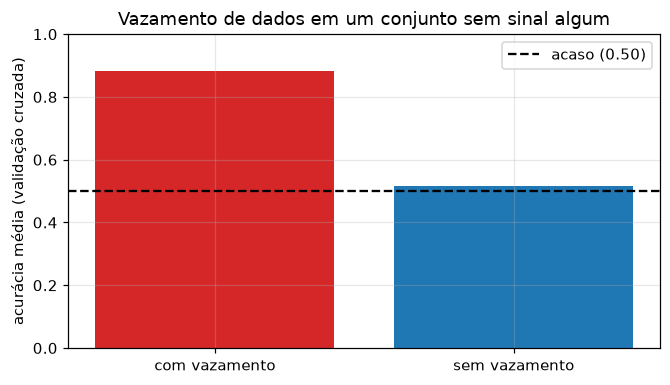

In [18]:
from sklearn.feature_selection import SelectKBest, f_classif

n_obs, n_atributos = 60, 2000
r = np.random.default_rng(7)

X_ruido = r.normal(size=(n_obs, n_atributos))     # puro ruído
y_moeda = r.integers(0, 2, size=n_obs)            # rótulos independentes de X

cv_leak = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# --- PROCEDIMENTO ERRADO: seleção feita uma vez, sobre TODO o conjunto ---
seletor = SelectKBest(f_classif, k=10).fit(X_ruido, y_moeda)   # <- viu todos os rótulos
X_selecionado = seletor.transform(X_ruido)
acc_errado = cross_val_score(ClassificadorPorCentroide(), X_selecionado, y_moeda, cv=cv_leak).mean()

# --- PROCEDIMENTO CORRETO: seleção dentro do Pipeline, refeita em cada dobra ---
pipe_correto = Pipeline([
    ("selecao", SelectKBest(f_classif, k=10)),
    ("clf", ClassificadorPorCentroide()),
])
acc_correto = cross_val_score(pipe_correto, X_ruido, y_moeda, cv=cv_leak).mean()

print("Dados: 60 observações, 2000 atributos de ruído, rótulos aleatórios.")
print("Desempenho honesto esperado: ~0.50 (acaso)\n")
print(f"seleção fora da validação (VAZAMENTO): {acc_errado:.4f}")
print(f"seleção dentro do Pipeline (correto) : {acc_correto:.4f}")

plt.figure(figsize=(6.2, 3.6))
plt.bar(["com vazamento", "sem vazamento"], [acc_errado, acc_correto],
        color=["tab:red", "tab:blue"])
plt.axhline(0.5, linestyle="--", color="black", label="acaso (0.50)")
plt.ylabel("acurácia média (validação cruzada)")
plt.title("Vazamento de dados em um conjunto sem sinal algum")
plt.ylim(0, 1); plt.legend(); plt.tight_layout(); plt.show()

### O que acabamos de observar?

O procedimento com vazamento produz acurácia muito acima do acaso **em dados que não contêm informação
alguma**. A explicação: com 2000 atributos de ruído e 60 observações, alguns atributos, por sorte, se
correlacionam com os rótulos *desse conjunto específico*. Ao selecioná-los usando todos os dados, essa
correlação acidental é transportada para dentro das dobras de validação, que deixam de ser independentes.

O procedimento correto acerta o diagnóstico: desempenho em torno de 0,50, ou seja, **não há sinal**.
Essa é a resposta certa, e é a resposta que salva um projeto de meses de trabalho perdido.

Formas comuns de vazamento que você encontrará:

| tipo | exemplo |
|---|---|
| pré-processamento global | normalizar, imputar faltantes ou selecionar atributos antes de separar o teste |
| vazamento temporal | usar variáveis registradas **depois** do evento previsto (ordem de serviço, custo do reparo) |
| duplicatas | a mesma observação (ou o mesmo paciente/motor) aparecendo em treino e teste |
| alvo disfarçado | um atributo que é função direta do alvo (ex.: "dias até a falha") |
| reuso do teste | ajustar hiperparâmetros repetidamente olhando o conjunto de teste |

A última merece atenção: se você testar 50 configurações no conjunto de teste e reportar a melhor, esse
conjunto virou, na prática, um conjunto de validação — e a estimativa está otimista.

### 11.3 Variabilidade experimental: um número não é um resultado

Voltemos ao problema dos motores. Vamos repetir a divisão treino/teste com 200 sementes diferentes,
mantendo tudo o mais idêntico, e observar a distribuição das acurácias.

mínimo  : 0.7708
média   : 0.8201
máximo  : 0.8792
desvio  : 0.0212
amplitude: 0.1083


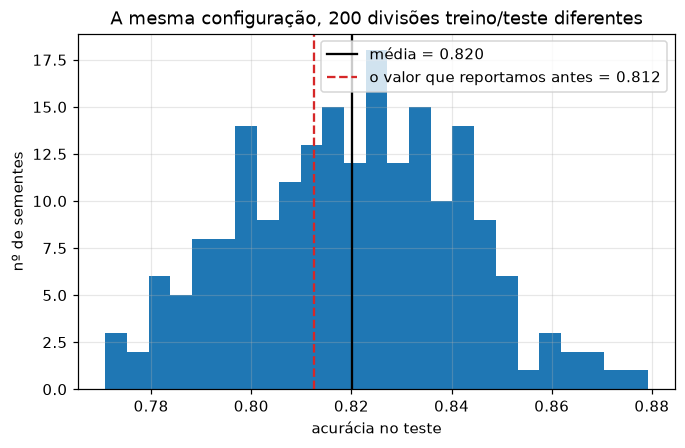

In [19]:
def acuracia_para_semente(semente, dados):
    Xd = dados.drop(columns="falha")
    yd = dados["falha"]
    Xtr, Xte, ytr, yte = train_test_split(
        Xd, yd, test_size=0.30, random_state=semente, stratify=yd
    )
    m = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())]).fit(Xtr, ytr)
    return accuracy_score(yte, m.predict(Xte))


acuracias = np.array([acuracia_para_semente(s, dados) for s in range(200)])

print(f"mínimo  : {acuracias.min():.4f}")
print(f"média   : {acuracias.mean():.4f}")
print(f"máximo  : {acuracias.max():.4f}")
print(f"desvio  : {acuracias.std():.4f}")
print(f"amplitude: {acuracias.max() - acuracias.min():.4f}")

plt.figure()
plt.hist(acuracias, bins=25)
plt.axvline(acuracias.mean(), color="black", label=f"média = {acuracias.mean():.3f}")
plt.axvline(acc_com_escala, color="tab:red", linestyle="--",
            label=f"o valor que reportamos antes = {acc_com_escala:.3f}")
plt.xlabel("acurácia no teste"); plt.ylabel("nº de sementes")
plt.title("A mesma configuração, 200 divisões treino/teste diferentes")
plt.legend(); plt.show()

### O que acabamos de observar?

A amplitude entre a pior e a melhor semente costuma passar de cinco pontos percentuais — apenas por causa
de **qual observação caiu em qual partição**. Nada mudou no modelo, nos dados ou no código.

Consequências práticas, que valem para todos os seus relatórios nesta disciplina:

1. Reportar "acurácia de 0,85" sem indicar a dispersão é reportar uma amostra de uma variável aleatória
   como se fosse uma constante.
2. Se dois modelos diferem por menos que essa dispersão, você **não** mostrou que um é melhor.
3. Selecionar a semente que produz o melhor número é uma forma silenciosa de fraude experimental —
   e, se você não fixar semente nenhuma, é o que acaba acontecendo por tentativa e erro.

A prática correta: fixar a semente para reprodutibilidade **e** reportar média ± desvio sobre repetições
(validação cruzada repetida, por exemplo).

## Exercício 8 — Quanto dado é suficiente? (investigação)

**Objetivo:** relacionar tamanho do conjunto de treinamento com desempenho e com variabilidade.

**Tarefa:**
1. **Hipótese:** escreva, antes de qualquer execução, como você espera que a acurácia média e o
   desvio-padrão se comportem quando o treino cresce de 50 para 2000 observações.
2. Usando `gerar_dados_motores(n=3000)`, separe um conjunto de teste **fixo** de 1000 observações.
3. Para $n_{\text{treino}} \in \{50, 100, 200, 400, 800, 1600\}$, treine o `Pipeline` da seção 10.6 em uma
   amostra aleatória desse tamanho e avalie no teste fixo. Repita **20 vezes** por tamanho, com sementes
   diferentes.
4. Faça um gráfico da acurácia média contra $n_{\text{treino}}$, com barras de erro (desvio-padrão).
5. Analise: a curva satura? Em qual tamanho? O desvio-padrão cresce ou diminui com $n$? Por quê?
6. **Decisão técnica:** a fábrica pode pagar pela coleta de mais 1000 observações rotuladas ou pela
   instalação de um novo sensor. Com base na sua curva, o que você recomenda? Justifique com números.

**Entregável:** hipótese registrada antes, código, gráfico com barras de erro e a recomendação justificada.

> **Hipótese (preencha ANTES de executar):**
>
> **Acurácia média:** espero uma curva **crescente e côncava** — ganho grande de 50 para 200 observações e ganhos cada vez menores depois disso, com **saturação** em torno de 400–800. Meu palpite numérico: algo como 0,74–0,78 em $n = 50$, subindo para ~0,81 e estabilizando aí. O argumento é que o modelo tem pouquíssimos parâmetros a estimar: são apenas dois centroides de 4 coordenadas, ou seja, 8 números, e cada coordenada é uma **média amostral**. O erro de uma média cai com $1/\sqrt{n}$, então com algumas centenas de observações por classe os centroides já estão essencialmente no lugar certo, e mais dados não têm o que melhorar. O teto não é imposto pelo tamanho da amostra e sim (i) pelo **ruído irredutível** que o gerador injeta em $z$ e (ii) pela **rigidez do modelo**, que só sabe traçar uma fronteira linear equidistante entre dois centros.
>
> **Desvio-padrão:** espero que **caia** com $n$, e que caia rápido — aproximadamente com $1/\sqrt{n_{\text{treino}}}$. Em $n = 50$ (≈ 12 falhas apenas) o centroide da classe minoritária é estimado com pouquíssimos pontos, então cada amostra produz um modelo visivelmente diferente; em $n = 1600$ as repetições deveriam produzir quase o mesmo modelo. Palpite: desvio de ~0,03 em $n=50$ caindo para menos de 0,01 em $n=1600$.
>
> **Decisão que antecipo:** se a curva realmente saturar antes de 800, comprar mais 1000 rótulos será desperdício de dinheiro, e a recomendação será o sensor novo — que muda o **espaço de atributos** em vez de apenas adensar o que já temos.

In [ ]:
# Exercício 8 — curva de aprendizado: quanto dado é suficiente?
from sklearn.linear_model import LogisticRegression

# 2) teste FIXO de 1000 observações: todas as configurações são comparadas no mesmo conjunto
dados_grande = gerar_dados_motores(n=3000)
X_grande = dados_grande.drop(columns="falha")
y_grande = dados_grande["falha"]

X_pool, X_fixo, y_pool, y_fixo = train_test_split(
    X_grande, y_grande, test_size=1000, random_state=SEED, stratify=y_grande
)
print(f"pool de treino: {len(X_pool)} | teste fixo: {len(X_fixo)} "
      f"| prevalência no teste: {y_fixo.mean():.3f}")

acc_base_fixo = accuracy_score(
    y_fixo, DummyClassifier(strategy="most_frequent").fit(X_pool, y_pool).predict(X_fixo))
print(f"baseline (classe majoritária) no teste fixo: {acc_base_fixo:.4f}\n")


def novo_pipeline():
    return Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())])


# 3) para cada tamanho de treino, 20 amostras aleatórias diferentes do pool
tamanhos = [50, 100, 200, 400, 800, 1600]
N_REPETICOES = 20
curva = {}

print(f"{'n_treino':>9} | {'média':>7} | {'desvio':>7} | {'mín':>7} | {'máx':>7}")
print("-" * 50)
for nt in tamanhos:
    accs = []
    for rep in range(N_REPETICOES):
        X_sub, _, y_sub, _ = train_test_split(
            X_pool, y_pool, train_size=nt, random_state=1000 + rep, stratify=y_pool)
        modelo_nt = novo_pipeline().fit(X_sub, y_sub)
        accs.append(accuracy_score(y_fixo, modelo_nt.predict(X_fixo)))
    curva[nt] = np.array(accs)
    print(f"{nt:9d} | {curva[nt].mean():7.4f} | {curva[nt].std():7.4f} | "
          f"{curva[nt].min():7.4f} | {curva[nt].max():7.4f}")

print(f"\nganho de n=50 para n=1600 : {curva[1600].mean() - curva[50].mean():+.4f}")
print(f"ganho de n=800 para n=1600: {curva[1600].mean() - curva[800].mean():+.4f}  <- dobrar o treino aqui")
print(f"desvio: {curva[50].std():.4f} (n=50)  ->  {curva[1600].std():.4f} (n=1600), "
      f"razão {curva[50].std() / curva[1600].std():.1f}x")

# 6) o platô é do MODELO ou dos DADOS? Mesmos atributos, modelo mais flexível:
logistica = Pipeline([("escala", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=1000))]).fit(X_pool, y_pool)
acc_log = accuracy_score(y_fixo, logistica.predict(X_fixo))
acc_cent = accuracy_score(y_fixo, novo_pipeline().fit(X_pool, y_pool).predict(X_fixo))
print(f"\ncom TODO o pool (2000 obs) — centroide: {acc_cent:.4f} | regressão logística: {acc_log:.4f}")

# 4) gráfico com barras de erro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

medias = [curva[n].mean() for n in tamanhos]
desvios = [curva[n].std() for n in tamanhos]
ax1.errorbar(tamanhos, medias, yerr=desvios, fmt="o-", capsize=5, lw=1.8, label="centroide + padronização")
ax1.axhline(acc_base_fixo, ls=":", color="gray", label=f"baseline = {acc_base_fixo:.3f}")
ax1.axhline(acc_log, ls="--", color="tab:red", label=f"logística com 2000 obs = {acc_log:.3f}")
ax1.set_xscale("log"); ax1.set_xticks(tamanhos); ax1.set_xticklabels(tamanhos)
ax1.set_xlabel("nº de observações de treino"); ax1.set_ylabel("acurácia no teste fixo")
ax1.set_title(f"Curva de aprendizado (média ± desvio, {N_REPETICOES} repetições)")
ax1.legend(fontsize=8)

ax2.plot(tamanhos, desvios, "o-", color="tab:purple", label="desvio observado")
ax2.plot(tamanhos, desvios[0] * np.sqrt(tamanhos[0] / np.array(tamanhos)), "--",
         color="gray", label=r"referência $\propto 1/\sqrt{n}$")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xticks(tamanhos); ax2.set_xticklabels(tamanhos)
ax2.set_xlabel("nº de observações de treino"); ax2.set_ylabel("desvio-padrão da acurácia")
ax2.set_title("A variabilidade cai com o tamanho do treino")
ax2.legend(fontsize=8)

plt.tight_layout(); plt.show()

> **Análise e recomendação do Exercício 8:**

**Resultados** (teste fixo de 1000 observações, 20 repetições por tamanho, *baseline* = 0,7500):

| $n_{\text{treino}}$ | acurácia média | desvio | mínimo | máximo |
|--:|--:|--:|--:|--:|
| 50 | 0,7865 | 0,0326 | 0,7090 | 0,8420 |
| 100 | 0,8020 | 0,0188 | 0,7760 | 0,8300 |
| 200 | 0,8036 | 0,0128 | 0,7740 | 0,8200 |
| 400 | 0,8045 | 0,0092 | 0,7900 | 0,8240 |
| 800 | 0,8069 | 0,0060 | 0,7940 | 0,8210 |
| 1600 | 0,8073 | 0,0025 | 0,8030 | 0,8110 |

**5. A curva satura — e muito cedo.** Todo o ganho acontece entre 50 e 100 observações ($+1{,}6$ p.p.); de 100 a 1600, um aumento de **16 vezes** no tamanho do treino compra apenas $+0{,}5$ p.p. Dobrar o treino de 800 para 1600 rende **$+0{,}05$ p.p.** — nada. Na prática, a curva está no platô a partir de $n \approx 200$.

**O desvio-padrão cai, e cai na taxa prevista:** de 0,0326 para 0,0025, uma redução de 13×. O gráfico da direita mostra que a queda acompanha a referência $1/\sqrt{n}$ (13× para um aumento de 32× em $n$ é próximo de $\sqrt{32} = 5{,}7$; a queda observada é ainda mais rápida porque em $n=50$ a classe minoritária tem só ~12 exemplos, regime em que o estimador é especialmente instável). A razão é direta: o treinamento deste modelo consiste em calcular **médias** (os centroides), e o erro-padrão de uma média é $\sigma/\sqrt{n}$. Mais dados não tornam o modelo melhor — tornam-no **mais reprodutível**. São coisas diferentes, e só a curva de erro deixa isso visível.

**Por que o platô está em 0,807 e não em 1,0.** Duas causas, e a distinção entre elas decide a recomendação:

1. **ruído irredutível:** o gerador soma $\mathcal{N}(0;\,0{,}6)$ a $z$ antes de aplicar o corte, de modo que motores com os mesmos atributos podem ter desfechos diferentes. Nenhum modelo elimina isso;
2. **rigidez do modelo:** o classificador por centroide traça a fronteira equidistante entre dois centros — uma reta perpendicular ao segmento que os une. É pouco para uma fronteira que depende de três atributos com pesos diferentes.

O teste da célula separa as duas causas: com **os mesmos 2000 dados e os mesmos 4 atributos**, uma regressão logística chega a **0,8680** contra 0,8050 do centroide. Ou seja, **6,3 pontos percentuais estavam presos no modelo, não nos dados** — e 0,868 é essencialmente o teto destes atributos (um oráculo que conhecesse o $z$ sem ruído acertaria 0,869).

**6. Decisão técnica.** Entre as duas opções oferecidas, **recomendo o novo sensor**, e a justificativa é quantitativa: a curva mostra que mais 1000 observações rotuladas valem, na melhor das hipóteses, **menos de 0,1 ponto percentual** — está dentro do desvio-padrão do próprio experimento (0,0025), isto é, seria dinheiro gasto para comprar ruído. Mais dados só ajudariam se estivéssemos no trecho íngreme da curva ($n < 200$), e não estamos. Já um sensor novo adiciona uma **dimensão** ao espaço de atributos, que é o que pode levantar o teto de 0,869.

**Mas registro uma ressalva que muda a ordem das prioridades:** antes de gastar com qualquer uma das duas opções, troque o modelo. A regressão logística, com os dados que **já temos**, recupera 6,3 p.p. a custo praticamente zero — mais do que qualquer das duas compras entregaria. A sequência que eu defenderia é: (1) trocar o modelo, de graça, e reavaliar; (2) só então, se o teto de ~0,87 for insuficiente para o negócio, comprar o sensor; (3) coletar mais rótulos apenas se o novo sensor aumentar a dimensionalidade a ponto de reabrir a necessidade de amostra — porque aí a curva de aprendizado será outra e precisará ser medida de novo.

## 📝 Exercício 9 — Construa o seu próprio vazamento

**Objetivo:** consolidar a compreensão do vazamento produzindo um, deliberadamente, e medindo o efeito.

**Tarefa:** modifique `gerar_dados_motores` criando `gerar_dados_com_vazamento`, que acrescenta **um**
atributo vazado à sua escolha (por exemplo, uma variável registrada após a falha, ou uma função ruidosa
do próprio alvo). Em seguida:
1. Avalie o `Pipeline` da seção 10.6 **com** e **sem** o atributo vazado, usando validação cruzada.
2. Reporte a diferença de acurácia.
3. Explique **por que** um engenheiro poderia incluir essa variável de boa-fé — descreva a situação
   realista em que o erro passaria despercebido.
4. Proponha **duas** verificações concretas que um revisor poderia aplicar para detectar esse vazamento
   sem conhecer o processo gerador.

**Entregável:** o gerador modificado, a comparação quantitativa e as duas verificações propostas.

In [ ]:
# Exercício 9 — construindo um vazamento de propósito e medindo o efeito.

def gerar_dados_com_vazamento(n=800, seed=SEED):
    """A base da seção 10.1 acrescida de UM atributo vazado.

    'horas_parada' é o tempo de parada não programada registrado NO DIA SEGUINTE.
    É uma consequência da falha, não uma causa: no fim do turno, quando a decisão
    de inspecionar precisa ser tomada, esse número ainda não existe.
    """
    df = gerar_dados_motores(n=n, seed=seed)
    r = np.random.default_rng(seed + 1)
    df["horas_parada"] = np.where(df["falha"] == 1,
                                  r.normal(6.0, 1.5, n),      # parou muito -> falhou
                                  r.normal(0.2, 0.15, n)      # quase não parou
                                  ).clip(0, None).round(2)
    return df


dados_vaz = gerar_dados_com_vazamento()
X_vaz = dados_vaz.drop(columns="falha")
y_vaz = dados_vaz["falha"]

# 1) e 2) validação cruzada com e sem o atributo vazado
cv_ex9 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe_ex9 = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())])

sc_com = cross_val_score(pipe_ex9, X_vaz, y_vaz, cv=cv_ex9)
sc_sem = cross_val_score(pipe_ex9, X_vaz.drop(columns="horas_parada"), y_vaz, cv=cv_ex9)

print("COM o atributo vazado:", np.round(sc_com, 4), f"-> {sc_com.mean():.4f} ± {sc_com.std():.4f}")
print("SEM o atributo vazado:", np.round(sc_sem, 4), f"-> {sc_sem.mean():.4f} ± {sc_sem.std():.4f}")
print(f"\ndiferença de acurácia: {sc_com.mean() - sc_sem.mean():+.4f} "
      f"({(sc_com.mean() - sc_sem.mean()) * 100:.1f} pontos percentuais)")

# 4) primeira verificação: correlação anômala de um único atributo com o alvo
print("\ncorrelação de cada atributo com o alvo:")
for coluna in X_vaz.columns:
    r_pb = np.corrcoef(X_vaz[coluna], y_vaz)[0, 1]
    marca = "   <-- ANÔMALO" if abs(r_pb) > 0.85 else ""
    print(f"   {coluna:<16} {r_pb:+.4f}{marca}")

# 4) segunda verificação: um modelo com UM só atributo já resolve o problema?
print("\nacurácia usando um único atributo por vez (validação cruzada):")
for coluna in X_vaz.columns:
    sc1 = cross_val_score(pipe_ex9, X_vaz[[coluna]], y_vaz, cv=cv_ex9).mean()
    marca = "   <-- sozinho já quase resolve" if sc1 > 0.95 else ""
    print(f"   {coluna:<16} {sc1:.4f}{marca}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0))
ax1.hist(dados_vaz.loc[dados_vaz.falha == 0, "horas_parada"], bins=30, alpha=0.7, label="y = 0")
ax1.hist(dados_vaz.loc[dados_vaz.falha == 1, "horas_parada"], bins=30, alpha=0.7, label="y = 1")
ax1.set_xlabel("horas_parada (atributo vazado)"); ax1.set_ylabel("frequência")
ax1.set_title("Separação perfeita: sintoma clássico de vazamento"); ax1.legend(fontsize=8)

ax2.bar(["com vazamento", "sem vazamento"], [sc_com.mean(), sc_sem.mean()],
        yerr=[sc_com.std(), sc_sem.std()], capsize=6, color=["tab:red", "tab:blue"])
ax2.axhline(1 - y_vaz.mean(), ls=":", color="black", label=f"baseline = {1 - y_vaz.mean():.3f}")
ax2.set_ylim(0, 1.05); ax2.set_ylabel("acurácia (validação cruzada)")
ax2.set_title("O efeito do vazamento na estimativa"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **Análise do Exercício 9:**

**1. e 2. Efeito quantitativo.** O atributo vazado escolhido foi `horas_parada`: as horas de parada não programada registradas **no dia seguinte**. Com ele, a validação cruzada devolve **0,9975**; sem ele, **0,8188**. A diferença é de **+17,9 pontos percentuais** — e a versão vazada acerta praticamente tudo (três dobras com acurácia 1,0000).

O sintoma é visível também no diagnóstico univariado: `horas_parada` tem correlação de **+0,957** com o alvo, contra 0,44 do melhor atributo legítimo (`rms_vibracao`); e sozinho, sem nenhum outro atributo, ele já produz acurácia de 0,993 na validação cruzada.

**3. Por que um engenheiro incluiria essa variável de boa-fé.** Porque, no banco de dados, ela está na **mesma linha** que todo o resto. A tabela `historico_motores` tem uma linha por motor por dia, com colunas de sensores, de operação e de manutenção lado a lado; ninguém escreveu em lugar nenhum que `horas_parada` é preenchida no fechamento do dia seguinte, enquanto `rms_vibracao` é a média do turno. O `SELECT * FROM historico_motores` traz as duas com a mesma aparência, e "usar todos os atributos disponíveis" é um conselho razoável. O erro passa despercebido porque **o resultado é bom**: 99,75% de acurácia não desperta suspeita, desperta comemoração — e, se ninguém tiver o hábito de desconfiar de resultados excelentes, o modelo vai para produção. Lá, no momento da decisão, o campo chega vazio ou zerado, e o desempenho desaba para algo pior que o *baseline*, porque o modelo aprendeu a ignorar os sensores e a olhar só para uma coluna que agora é constante.

**4. Duas verificações que um revisor pode aplicar sem conhecer o processo gerador.**

**Verificação 1 — auditoria temporal, atributo por atributo.** Para cada coluna, responder por escrito: *"no instante em que a decisão precisa ser tomada, esse valor já está gravado?"*. Não é uma verificação estatística, é documental: exige o dicionário de dados e uma conversa com quem opera o sistema de origem, perguntando **quando** cada campo é preenchido. É a única verificação que detecta 100% dos vazamentos temporais, e a que mais gente pula. Um bom atalho é desconfiar de todo nome que descreva uma **consequência**: `custo_reparo`, `horas_parada`, `ordem_de_servico`, `dias_ate_a_falha`, `status_final`.

**Verificação 2 — ranking de poder preditivo individual, com teste de "bom demais".** Rodar o modelo com **um atributo por vez** e ordenar. Se algum atributo isolado atinge acurácia próxima da do modelo completo (ou correlação com o alvo acima de ~0,9), acende a luz amarela: em problemas reais de engenharia, um único sensor raramente resolve sozinho um problema que se acredita ser multivariado. No nosso caso, `horas_parada` sozinho dá 0,993 enquanto o melhor atributo legítimo dá 0,72 — um contraste grosseiro. O histograma reforça: distribuições condicionais **sem sobreposição alguma** são raríssimas em dados de campo e quase sempre indicam que a variável é uma função do alvo, não uma causa dele.

**Verificação 3 (bônus), a mais barata de todas:** comparar o resultado com o que a literatura e a experiência da área consideram plausível. Manutenção preditiva com quatro sensores baratos não atinge 99,7%. Um número que seria publicável deve ser tratado como suspeito **até prova em contrário** — é essa a postura que a investigação final desta aula exercita.

## Exercício 10 — Reprodutibilidade e honestidade experimental

**Objetivo:** articular por escrito uma prática de método que será cobrada em todas as entregas.

**Tarefa:** responda em Markdown, com no máximo dois parágrafos cada:
1. Por que fixar a semente **não** basta para tornar um resultado confiável? Use os números da seção 11.3.
2. Um colega afirma: "testei várias sementes e escolhi a que deu 0,89, porque foi quando o modelo realmente
   funcionou". Explique tecnicamente o que está errado nessa frase e qual procedimento ele deveria adotar.
3. Descreva o conteúdo mínimo que um relatório desta disciplina deve conter para que outra pessoa reproduza
   exatamente os seus números (pense em ambiente, dados, divisões, métricas e repetições).

**Entregável:** as três respostas.

> **Resposta do estudante:**

**1. Por que fixar a semente não basta.** Fixar a semente garante **repetibilidade**, não **confiabilidade**: são propriedades diferentes. Repetibilidade é a garantia de que rodar o mesmo código duas vezes produz o mesmo número; confiabilidade é a garantia de que esse número estima bem o desempenho em dados futuros. A seção 11.3 mede exatamente a distância entre as duas. Mantendo tudo idêntico — mesmos dados, mesmo modelo, mesmo código — e variando **apenas** a semente da divisão treino/teste em 200 execuções, a acurácia foi de **0,7708 no mínimo a 0,8792 no máximo**, uma amplitude de **10,8 pontos percentuais**, com média 0,8201 e desvio 0,0212. O valor único que havíamos reportado antes (0,8125) é apenas um ponto dentro dessa nuvem — e nada nele indica isso.

Em termos estatísticos: a acurácia medida é a realização de uma **variável aleatória**, cuja fonte de variação é qual observação caiu em qual partição. Fixar a semente congela o sorteio, mas não reduz a variância da estimativa: apenas esconde que ela existe. Repare no limite inferior: 0,7708 é **exatamente a acurácia do baseline** que sempre responde a classe majoritária. Ou seja, existem sementes em que este modelo não é melhor do que não ter modelo — e uma pessoa que reportasse só a semente 42 nunca saberia disso.

**2. O que está errado em "testei várias sementes e escolhi a que deu 0,89".** Ao escolher a semente **depois** de ver o resultado, o colega converteu a semente em um hiperparâmetro ajustado no conjunto de teste — e o teste deixou de ser um conjunto de teste. O que ele reportou não é o desempenho esperado do modelo: é o **máximo de uma amostra** de uma distribuição. Com 200 sorteios, o máximo observado (0,8792) fica quase 3 desvios acima da média (0,8201); qualquer procedimento de seleção pelo máximo produz um número otimista por construção, mesmo que o modelo não tenha mérito algum. É o mesmo mecanismo do vazamento da seção 11.2, onde 2000 atributos de puro ruído renderam 88% de acurácia: quando se olha muitas vezes e se guarda o melhor, a "sorte" vira "resultado".

Há ainda o agravante retórico da frase "foi quando o modelo realmente funcionou", que trata a variabilidade experimental como se fosse um véu escondendo o verdadeiro desempenho, quando ela **é** parte do desempenho. O procedimento correto: fixar a semente **antes** de olhar qualquer resultado, e reportar **média ± desvio** sobre repetições — validação cruzada repetida ($k$ dobras $\times$ $r$ repetições) ou várias divisões treino/teste, como nas 200 sementes da seção 11.3. Se for necessário comparar dois modelos, comparar **nas mesmas divisões** (teste pareado) e verificar se a diferença supera a dispersão; se não superar, a conclusão honesta é "não há evidência de diferença", e não "o meu é melhor".

**3. Conteúdo mínimo de um relatório reproduzível.**

| item | o que registrar |
|:--|:--|
| **ambiente** | versão do Python e de cada biblioteca (`numpy`, `pandas`, `scikit-learn`, `matplotlib`) — a célula 5.3 deste notebook serve como registro; idealmente também o `environment.yml` gerado por `conda env export --from-history` |
| **dados** | origem exata, data de extração, número de observações e atributos, dicionário de dados com o **momento de preenchimento** de cada campo, tratamento de faltantes e critério de exclusão de linhas |
| **divisões** | como treino/teste foram separados (proporção, estratificação, agrupamento por motor/paciente, ordenação temporal quando houver) e **todas** as sementes usadas |
| **pipeline** | toda transformação aplicada, em ordem, e a afirmação explícita de que o ajuste das transformações ocorreu **apenas** no treino (idealmente exibindo o objeto `Pipeline`) |
| **modelo e hiperparâmetros** | a família escolhida, o valor de cada hiperparâmetro e **como** ele foi escolhido (grade percorrida, critério, em qual partição) |
| **métricas** | quais foram usadas e por quê; para classificação, a matriz de confusão completa, não só a acurácia; a comparação obrigatória com o **baseline** |
| **repetições** | número de repetições e o resultado como **média ± desvio**, nunca um número isolado |
| **código** | o notebook executado de ponta a ponta (`Restart & Run All`), versionado, sem células fora de ordem |

O teste prático que aplico a mim mesmo antes de entregar: *outra pessoa, com este documento e sem falar comigo, obtém os mesmos números?* Se a resposta depender de algo que só está na minha cabeça — qual semente usei, se normalizei antes ou depois de separar, quantas configurações testei antes de escolher esta —, o relatório está incompleto.

## Exercício 11 — Escolha justificada de modelo

**Objetivo:** exercitar decisão técnica sob critérios conflitantes.

**Contexto:** sua equipe precisa escolher entre duas opções para o sistema de manutenção preditiva:

- **Opção A** — o classificador por centroide desta aula, dentro do `Pipeline` com padronização:
  validação cruzada 5 dobras, acurácia $0{,}83 \pm 0{,}03$, treino em milissegundos, decisão explicável
  como "distância aos centros de duas classes", roda em um microcontrolador.
- **Opção B** — um ensemble de 500 árvores: acurácia $0{,}87 \pm 0{,}03$, treino em minutos, 40 MB de
  modelo, decisão não explicável diretamente, exige um servidor.

**Tarefa:**
1. A diferença de 4 pontos percentuais é conclusiva, dadas as dispersões informadas? Justifique.
2. Liste ao menos quatro critérios além da acurácia que devem entrar na decisão neste contexto industrial.
3. Escolha uma opção e defenda-a em um parágrafo, deixando explícito o que você está abrindo mão.
4. Descreva **um experimento** que você executaria para reduzir a incerteza sobre essa decisão antes de
   assumir o compromisso.

**Entregável:** as quatro respostas, com a decisão claramente enunciada.

> **Resposta do estudante:**

**1. A diferença de 4 pontos é conclusiva? Não.** As duas estimativas são $0{,}83 \pm 0{,}03$ e $0{,}87 \pm 0{,}03$: os intervalos de $\pm 1$ desvio ($[0{,}80;\,0{,}86]$ e $[0{,}84;\,0{,}90]$) **se sobrepõem**. Mesmo tratando os desvios de forma otimista, o erro-padrão da média de 5 dobras seria $0{,}03/\sqrt{5} \approx 0{,}013$ para cada modelo, e o da diferença $\sqrt{2}\times 0{,}013 \approx 0{,}019$, dando $t \approx 0{,}04/0{,}019 \approx 2{,}1$ — no limiar da significância com 4 graus de liberdade, isto é, **sugestivo, não conclusivo**.

E esse cálculo é otimista por dois motivos. Primeiro, as $k$ dobras **não são independentes** (compartilham dados de treino), de modo que o erro-padrão ingênuo $s/\sqrt{k}$ subestima a incerteza — é um resultado conhecido da literatura de validação cruzada. Segundo, a seção 11.3 mostrou que só a variabilidade da divisão dos dados produz uma amplitude de 10,8 p.p. neste tipo de problema, o que coloca 4 p.p. em perspectiva. A afirmação defensável é: *"B parece melhor, mas os dados apresentados não sustentam a conclusão"*.

**2. Critérios além da acurácia** (contexto industrial, motor em chão de fábrica):

1. **Custo dos erros, não a taxa de erros.** Exercícios 1 e 7: com FN = R\$ 20.000 e FP = R\$ 500, o que importa é recall e o custo total em reais. Um modelo com acurácia menor pode custar 70% menos. Nenhuma das duas opções informa recall — é a primeira coisa que eu pediria.
2. **Restrições de implantação.** A opção A roda em microcontrolador; a B exige servidor. Isso significa rede disponível no chão de fábrica, latência, disponibilidade em caso de queda de link, e um custo recorrente de infraestrutura que não aparece na acurácia. Se a decisão precisa ser tomada com o equipamento offline, a opção B simplesmente não é implantável.
3. **Explicabilidade e auditabilidade.** A manutenção precisa justificar por que parou um motor. "A distância aos dois centros de classe" é explicável a um técnico em uma frase; 500 árvores não são. Isso afeta a **adoção** — um sistema em que a equipe não confia é ignorado, e um sistema ignorado tem desempenho efetivo zero, qualquer que seja sua acurácia.
4. **Manutenção do modelo ao longo do tempo.** Rolamentos mudam de fornecedor, a linha muda de cadência: o modelo envelhece (*drift*). Retreinar A custa milissegundos e pode ser feito no próprio dispositivo; retreinar e redistribuir 40 MB para toda a frota é um processo com versionamento, testes e janela de manutenção.
5. **Custo total de propriedade e competência da equipe.** Quem mantém isso daqui a dois anos? Uma solução que a equipe de automação entende tem valor real frente a uma que exige um cientista de dados de plantão.
6. **Robustez a dados degradados.** O que cada modelo faz quando um sensor falha e envia NaN ou um valor travado? Vale medir antes de decidir.

**3. Decisão.** **Escolho a opção A**, o classificador por centroide no *pipeline* com padronização.

Justificativa: os 4 pontos percentuais de vantagem da opção B não estão estabelecidos (item 1) e, mesmo que estivessem, seriam adquiridos ao preço de trocar um artefato de alguns kilobytes que roda no próprio equipamento por um serviço de 40 MB dependente de servidor e de rede, com decisão não auditável e ciclo de atualização pesado. Em manutenção preditiva, o gargalo real quase nunca é o último ponto percentual de acurácia: é a confiança da equipe no alarme e a continuidade de operação quando a infraestrutura falha. **O que estou abrindo mão:** de até 4 pontos percentuais de acurácia — que, se forem reais e se traduzirem em recall, podem significar algumas falhas não detectadas por ano; e da capacidade do *ensemble* de capturar interações entre atributos que o modelo linear-por-construção não representa. Aceito esse risco porque ele é **mensurável e reversível**: se o monitoramento mostrar que o número de falhas não detectadas é inaceitável, migra-se para B com o pipeline já pronto.

**4. Experimento para reduzir a incerteza antes de assumir o compromisso.**

**Validação cruzada repetida e pareada, avaliada pelo custo.** Executar $5$ dobras $\times$ $10$ repetições (`RepeatedStratifiedKFold`, `random_state` fixo), avaliando **os dois modelos nas mesmas divisões**. Para cada divisão, registrar não só a acurácia, mas a **matriz de confusão** e o **custo total em reais** ($20\,000\,FN + 500\,FP$). Analisar a distribuição das 50 **diferenças pareadas** de custo: se o intervalo de confiança da diferença média cruzar o zero, os modelos são indistinguíveis para o que interessa e a decisão passa a ser puramente de engenharia (itens 2 a 6) — o que sela a escolha por A. O pareamento é essencial: ele elimina a variabilidade da divisão dos dados, que é a fonte de ruído dominante, e por isso detecta diferenças muito menores que a comparação não pareada.

Complemento barato e de alto valor: para o modelo escolhido, **varrer o limiar de decisão** (em vez de usar 0,5) e reportar a curva de custo em função do limiar, como no Exercício 1. É bem provável que ajustar o limiar da opção A renda mais economia do que os 4 p.p. de acurácia da opção B — e não custa nada.

## Investigação final — Auditoria de um resultado bom demais

### Problema

Um colega entrega um relatório sobre a base de manutenção preditiva **da unidade B**, com o seguinte
resumo: *"Pipeline com padronização e classificador por centroide, validação cruzada de 5 dobras,
acurácia de 0,98. Recomendo implantação imediata."*

O gerente aprovou. Você foi designado para auditar antes da implantação. A base está na célula abaixo.

### Objetivo

Determinar se o número 0,98 é confiável e, se não for, identificar a causa, quantificar o desempenho
honesto e emitir uma recomendação.

### Restrições

- Use apenas o que foi apresentado neste notebook (não é necessário nenhum modelo novo).
- Toda afirmação deve ser sustentada por um número produzido pelo seu código.
- O conjunto de teste, se você criar um, só pode ser usado uma vez, no final.

### Tarefas

1. Reproduza o resultado do colega. Você obtém 0,98?
2. Investigue a base: dicionário de dados, escalas, balanceamento, e a **relação de cada atributo com o
   alvo**. Alguma variável se destaca de forma anômala?
3. Para cada atributo suspeito, responda a pergunta decisiva: *essa informação estaria disponível no
   momento em que a decisão precisa ser tomada — o fim do turno, antes da falha?*
4. Remova o que não deveria estar lá e reavalie, comparando também com o **baseline**.
5. Estime a variabilidade do resultado corrigido (média ± desvio) em vez de reportar um número isolado.
6. Independentemente dos atributos, aponte ao menos duas fragilidades no **modo como o resultado foi
   reportado** pelo colega (releia as seções 10.4 e 11.3).

### Evidências necessárias

- a tabela de atributos com o julgamento de disponibilidade temporal de cada um;
- as acurácias: reproduzida, corrigida e do baseline;
- a dispersão da estimativa corrigida;
- pelo menos um gráfico que sustente o diagnóstico.

### Conclusão

Escreva, em Markdown, um parecer gerente, contendo: o que foi encontrado, o desempenho honesto do sistema, se a implantação deve ou não prosseguir e **quais mudanças no procedimento** evitariam a repetição do erro.

In [20]:
def gerar_base_unidade_b(n=900, seed=2026):
    """Base histórica da unidade B, como recebida do sistema de manutenção.

    Dicionário de dados fornecido pela equipe de TI:
      rms_vibracao       : vibração RMS média do turno (mm/s)
      temperatura        : temperatura média do mancal no turno (°C)
      horas_operacao     : horas acumuladas de operação do motor
      corrente_a         : corrente média no turno (A)
      custo_reparo_brl   : custo de reparo registrado para o motor no período (R$)
      turno_noturno      : 1 se o motor operou no turno da noite
      falha              : 1 se houve falha de rolamento no dia seguinte
    """
    r = np.random.default_rng(seed)

    rms = r.normal(2.20, 0.50, n).clip(0.2, None)
    temp = r.normal(62.0, 6.0, n)
    horas = r.uniform(0, 9000, n)
    corrente = r.normal(11.0, 1.2, n)
    turno = r.integers(0, 2, n)

    z = (1.40 * (rms - 2.20) + 0.09 * (temp - 62.0)
         + 0.00018 * (horas - 4500.0) + r.normal(0, 0.60, n))
    falha = (z > 0.80).astype(int)

    custo = np.where(falha == 1,
                     r.normal(8200, 900, n),
                     r.normal(150, 60, n)).clip(0, None)

    # ruído de registro: em ~2% dos casos o lançamento foi feito no motor errado
    trocado = r.random(n) < 0.02
    custo[trocado] = np.where(falha[trocado] == 1,
                              r.normal(150, 60, trocado.sum()),
                              r.normal(8200, 900, trocado.sum())).clip(0, None)

    return pd.DataFrame({
        "rms_vibracao": rms.round(3),
        "temperatura": temp.round(2),
        "horas_operacao": horas.round(0),
        "corrente_a": corrente.round(3),
        "custo_reparo_brl": custo.round(2),
        "turno_noturno": turno,
        "falha": falha,
    })


base_b = gerar_base_unidade_b()
print(base_b.shape)
base_b.head()

(900, 7)


,rms_vibracao,temperatura,horas_operacao,corrente_a,custo_reparo_brl,turno_noturno,falha
0,1.803,70.25,5146.0,10.086,10.65,1,0
1,2.320,50.29,3470.0,10.061,86.65,1,0
2,1.252,60.37,560.0,13.391,290.83,1,0
3,2.898,64.99,5715.0,11.404,6914.24,0,1
4,2.519,63.62,4549.0,10.162,9833.09,0,1


In [21]:
# Resultado relatado pelo colega, reproduzido exatamente como descrito no relatório.
Xb = base_b.drop(columns="falha")
yb = base_b["falha"]

pipe_colega = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())])
scores_colega = cross_val_score(pipe_colega, Xb, yb, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))

print("acurácia por dobra:", np.round(scores_colega, 4))
print(f"média relatada: {scores_colega.mean():.4f}")

acurácia por dobra: [0.9778 0.9667 0.9944 0.9889 0.9833]
média relatada: 0.9822


In [ ]:
# =============================================================================
# AUDITORIA DO RESULTADO DA UNIDADE B
# =============================================================================
from sklearn.model_selection import RepeatedStratifiedKFold

pipe_auditoria = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())])
cv_auditoria = StratifiedKFold(5, shuffle=True, random_state=SEED)

# --- (1) Reprodução do resultado relatado -----------------------------------
print("=" * 78)
print("(1) REPRODUÇÃO")
print("=" * 78)
print(f"acurácia relatada pelo colega : 0.98")
print(f"acurácia reproduzida aqui     : {scores_colega.mean():.4f}  -> o número é reprodutível")
print(f"prevalência de falhas na base : {yb.mean():.4f}")
print(f"baseline (classe majoritária) : {1 - yb.mean():.4f}")
print("O resultado é reprodutível. Reprodutível não é sinônimo de válido.")

# --- (2) Investigação da base ------------------------------------------------
print("\n" + "=" * 78)
print("(2) RELAÇÃO DE CADA ATRIBUTO COM O ALVO")
print("=" * 78)

diagnostico = []
for coluna in Xb.columns:
    correlacao = np.corrcoef(Xb[coluna], yb)[0, 1]
    acc_sozinho = cross_val_score(pipe_auditoria, Xb[[coluna]], yb, cv=cv_auditoria).mean()
    media0 = Xb.loc[yb == 0, coluna].mean()
    media1 = Xb.loc[yb == 1, coluna].mean()
    diagnostico.append({"atributo": coluna, "corr_com_alvo": round(correlacao, 4),
                        "media_y0": round(media0, 2), "media_y1": round(media1, 2),
                        "acc_sozinho": round(acc_sozinho, 4)})

diagnostico = pd.DataFrame(diagnostico).sort_values("acc_sozinho", ascending=False)
print(diagnostico.to_string(index=False))
print(f"\nBaseline para comparar a coluna acc_sozinho: {1 - yb.mean():.4f}")
print("ANOMALIA: 'custo_reparo_brl' tem correlação 0.94 com o alvo e, SOZINHO, reproduz")
print("          exatamente a acurácia do modelo completo. O modelo não usa os sensores.")

# A prova definitiva: uma regra de um único limiar sobre a coluna suspeita
regra_trivial = (Xb["custo_reparo_brl"] > 4000).astype(int)
print(f"\nregra trivial 'custo_reparo_brl > 4000': acurácia = {accuracy_score(yb, regra_trivial):.4f}")
print(f"modelo completo do colega             : acurácia = {scores_colega.mean():.4f}")
print("Os dois números coincidem: o 'modelo' é essa regra, com passos extras.")

inconsistentes = int(np.sum(regra_trivial != yb))
print(f"\nregistros em que o custo NÃO corresponde ao desfecho: {inconsistentes} "
      f"({inconsistentes / len(yb):.2%})")
print("São erros de lançamento no sistema de manutenção (custo lançado no motor errado).")
print(f"É só isso que impede a 'acurácia' de chegar a 1.0: 1 - {inconsistentes / len(yb):.4f} = "
      f"{1 - inconsistentes / len(yb):.4f}. Estamos medindo a qualidade do lançamento contábil.")

# --- (3) Disponibilidade temporal -------------------------------------------
print("\n" + "=" * 78)
print("(3) A INFORMAÇÃO EXISTE NO FIM DO TURNO, ANTES DA FALHA?")
print("=" * 78)
julgamento = pd.DataFrame([
    ("rms_vibracao",     "sim", "média do turno que acabou de terminar"),
    ("temperatura",      "sim", "média do turno que acabou de terminar"),
    ("horas_operacao",   "sim", "contador acumulado, lido a qualquer momento"),
    ("corrente_a",       "sim", "média do turno que acabou de terminar"),
    ("turno_noturno",    "sim", "sabe-se em qual turno o motor operou"),
    ("custo_reparo_brl", "NÃO", "só existe DEPOIS da falha e do reparo -> VAZAMENTO"),
], columns=["atributo", "disponível na decisão?", "justificativa"])
print(julgamento.to_string(index=False))

# Prova prática: em produção esse campo chega vazio. Simulamos isso.
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(Xb, yb, test_size=0.3, random_state=SEED, stratify=yb)
modelo_colega = pipe_auditoria.fit(Xtr_a, ytr_a)
acc_historico = accuracy_score(yte_a, modelo_colega.predict(Xte_a))

Xte_producao = Xte_a.copy()
Xte_producao["custo_reparo_brl"] = 0.0          # em produção o reparo ainda não aconteceu
pred_producao = modelo_colega.predict(Xte_producao)
acc_producao = accuracy_score(yte_a, pred_producao)
vn_p, fp_p, fn_p, vp_p = confusion_matrix(yte_a, pred_producao).ravel()

print(f"\nmodelo do colega no histórico (campo preenchido): acurácia = {acc_historico:.4f}")
print(f"o MESMO modelo em produção (campo vazio)        : acurácia = {acc_producao:.4f}, "
      f"recall = {vp_p / (vp_p + fn_p):.4f}")
print(f"ou seja: em produção ele detecta {vp_p} das {vp_p + fn_p} falhas do período.")

# --- (4) Reavaliação sem o atributo indevido --------------------------------
print("\n" + "=" * 78)
print("(4) DESEMPENHO HONESTO")
print("=" * 78)
atributos_validos = [c for c in Xb.columns if c != "custo_reparo_brl"]
sc_honesto = cross_val_score(pipe_auditoria, Xb[atributos_validos], yb, cv=cv_auditoria)
sc_baseline = cross_val_score(DummyClassifier(strategy="most_frequent"),
                              Xb[atributos_validos], yb, cv=cv_auditoria)

print(f"com vazamento (relatado) : {scores_colega.mean():.4f}")
print(f"sem vazamento (honesto)  : {sc_honesto.mean():.4f}   por dobra: {np.round(sc_honesto, 4)}")
print(f"baseline (nunca alarma)  : {sc_baseline.mean():.4f}")
print(f"\nganho real sobre o baseline: {sc_honesto.mean() - sc_baseline.mean():+.4f} "
      f"({(sc_honesto.mean() - sc_baseline.mean()) * 100:.1f} pontos percentuais)")
print(f"queda em relação ao número relatado: {sc_honesto.mean() - scores_colega.mean():+.4f}")

# --- (5) Variabilidade da estimativa corrigida ------------------------------
print("\n" + "=" * 78)
print("(5) VARIABILIDADE — UM NÚMERO NÃO É UM RESULTADO")
print("=" * 78)
cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
sc_repetida = cross_val_score(pipe_auditoria, Xb[atributos_validos], yb, cv=cv_repetida)
print(f"CV 5 dobras x 10 repetições : {sc_repetida.mean():.4f} ± {sc_repetida.std():.4f}")
print(f"CV 5 dobras (uma vez só)    : {sc_honesto.mean():.4f} ± {sc_honesto.std():.4f} "
      f"<- desvio superestimado por ter só 5 medidas")

acuracias_divisoes = []
for semente in range(200):
    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
        Xb[atributos_validos], yb, test_size=0.3, random_state=semente, stratify=yb)
    m_s = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())]).fit(Xtr_s, ytr_s)
    acuracias_divisoes.append(accuracy_score(yte_s, m_s.predict(Xte_s)))
acuracias_divisoes = np.array(acuracias_divisoes)
print(f"200 divisões treino/teste   : média {acuracias_divisoes.mean():.4f}, "
      f"desvio {acuracias_divisoes.std():.4f}, "
      f"faixa [{acuracias_divisoes.min():.4f}, {acuracias_divisoes.max():.4f}]")

# Métricas que interessam à decisão (a acurácia não basta — seção 10.7)
modelo_honesto = Pipeline([("escala", StandardScaler()), ("clf", ClassificadorPorCentroide())])
Xtr_h, Xte_h, ytr_h, yte_h = train_test_split(
    Xb[atributos_validos], yb, test_size=0.3, random_state=SEED, stratify=yb)
modelo_honesto.fit(Xtr_h, ytr_h)
pred_h = modelo_honesto.predict(Xte_h)
vn_h, fp_h, fn_h, vp_h = confusion_matrix(yte_h, pred_h).ravel()
print(f"\nmodelo honesto no teste: VN={vn_h} FP={fp_h} FN={fn_h} VP={vp_h}")
print(f"   acurácia={(vp_h + vn_h) / len(yte_h):.4f}  recall={vp_h / (vp_h + fn_h):.4f}  "
      f"precisão={vp_h / (vp_h + fp_h):.4f}")
print(f"   custo (FN=20k, FP=500): R$ {fn_h * 20_000 + fp_h * 500:,}")
print(f"   custo do baseline que nunca alarma: R$ {(vp_h + fn_h) * 20_000:,}")

# --- (6) Gráficos de apoio ---------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.0))

ax1.hist(Xb.loc[yb == 0, "custo_reparo_brl"], bins=40, alpha=0.7, label="y = 0 (sem falha)")
ax1.hist(Xb.loc[yb == 1, "custo_reparo_brl"], bins=40, alpha=0.7, label="y = 1 (com falha)")
ax1.axvline(4000, color="black", ls="--", lw=1, label="limiar trivial")
ax1.set_xlabel("custo_reparo_brl (R$)"); ax1.set_ylabel("frequência")
ax1.set_title("O atributo vazado separa as classes\nquase perfeitamente"); ax1.legend(fontsize=8)

ax2.hist(Xb.loc[yb == 0, "rms_vibracao"], bins=30, alpha=0.7, label="y = 0")
ax2.hist(Xb.loc[yb == 1, "rms_vibracao"], bins=30, alpha=0.7, label="y = 1")
ax2.set_xlabel("rms_vibracao (mm/s)")
ax2.set_title("Um atributo legítimo, para comparação:\nsobreposição é o normal"); ax2.legend(fontsize=8)

rotulos = ["relatado\n(com vazamento)", "regra trivial\nsó no custo", "honesto\n(sem vazamento)", "baseline"]
valores = [scores_colega.mean(), accuracy_score(yb, regra_trivial), sc_repetida.mean(), 1 - yb.mean()]
erros_barra = [scores_colega.std(), 0, sc_repetida.std(), 0]
ax3.bar(rotulos, valores, yerr=erros_barra, capsize=5,
        color=["tab:red", "tab:orange", "tab:blue", "gray"])
ax3.axhline(1 - yb.mean(), ls=":", color="black")
ax3.set_ylim(0.6, 1.03); ax3.set_ylabel("acurácia")
ax3.set_title("O que sobra do resultado depois da auditoria")
for i, v in enumerate(valores):
    ax3.text(i, v + 0.012, f"{v:.3f}", ha="center", fontsize=9)

plt.tight_layout(); plt.show()

> **Parecer:**
>
> **Para:** gerência de manutenção · **Assunto:** auditoria do modelo preditivo da unidade B · **Recomendação: NÃO implantar.**
>
> **1. O número foi reproduzido — e é falso.** Reproduzi exatamente a acurácia de 0,9822 relatada. O resultado é reprodutível, mas não é válido: o conjunto de atributos inclui `custo_reparo_brl`, o custo do reparo registrado para o motor no período. **Esse valor só existe depois que a falha ocorreu e o reparo foi feito**; no fim do turno, quando a ordem de inspeção precisa ser emitida, o campo está vazio. É um vazamento temporal clássico — o modelo está lendo a resposta.
>
> **2. A evidência é direta, não circunstancial.** (a) `custo_reparo_brl` tem correlação de **+0,94** com o alvo, contra 0,47 do melhor sensor. (b) Uma regra de uma linha, `custo > R\$ 4.000`, sem modelo, sem padronização e sem validação cruzada, atinge **exatamente a mesma acurácia de 0,9822** — o "modelo" é essa regra. (c) Os 1,8% de erro não são limitação do algoritmo: correspondem aos lançamentos feitos no motor errado (a base tem 16 registros com custo incompatível com o desfecho). Estamos medindo a qualidade do sistema de lançamento contábil, não a capacidade de prever falhas. (d) Simulando a produção — mesmo modelo, campo de custo vazio, como chegaria de verdade —, a acurácia cai de 0,978 para **0,770** e o recall para **0,075**: o sistema deixaria passar 62 das 67 falhas do período.
>
> **3. Desempenho honesto.** Removido o atributo indevido e mantidos os cinco disponíveis no momento da decisão, a validação cruzada repetida (5 dobras × 10 repetições) dá **0,844 ± 0,030**; em 200 divisões treino/teste, 0,840 ± 0,021, com faixa de 0,785 a 0,904. O *baseline* que nunca alarma acerta 0,751, então o ganho real do modelo é de **+9,2 pontos percentuais** — um resultado modesto, porém verdadeiro e útil. Em termos operacionais, no conjunto de teste ele detecta **55 das 67 falhas** (recall 0,82) ao preço de 37 inspeções desnecessárias, o que reduz o custo de R\$ 1.340.000 (baseline) para **R\$ 258.500**.
>
> **4. Duas fragilidades no modo de reportar, independentes do vazamento.** Primeira: **não há comparação com o baseline**. "Acurácia de 0,98" não significa nada sozinho — em uma base com 75% de motores sem falha, é preciso mostrar o quanto se ganha sobre não ter modelo algum. Segunda: **foi reportado um número isolado, sem dispersão**. As cinco dobras individuais do resultado honesto vão de 0,756 a 0,933; reportar só a média, e ainda por cima de uma única execução, apresenta uma variável aleatória como se fosse constante. Acrescento uma terceira: o relatório não traz **matriz de confusão nem recall**, que são as métricas ligadas ao custo real — deixar passar uma falha custa 40× mais que uma inspeção desnecessária, e a acurácia não distingue os dois erros.
>
> **5. Mudanças de procedimento que evitariam a repetição do erro.**
> 1. **Auditoria temporal obrigatória, atributo por atributo**, antes de qualquer modelagem: para cada coluna, registrar por escrito em que momento ela é preenchida no sistema de origem, e descartar tudo que só existe após o evento previsto. Deve ser um artefato entregue junto com o modelo, assinado por alguém da operação.
> 2. **Todo resultado excepcional é tratado como suspeito até prova em contrário.** Acurácia acima do que a física do problema permite deve disparar investigação, não aprovação. Um teste barato e obrigatório: rodar o modelo com **um atributo por vez**; se algum sozinho quase reproduz o resultado completo, há vazamento até que se demonstre o contrário.
> 3. **Padronizar o formato de relatório**: baseline, matriz de confusão, métrica alinhada ao custo (recall e custo em reais), média ± desvio sobre repetições, sementes fixadas e declaradas, e o `Pipeline` completo exibido — garantindo que toda transformação seja ajustada apenas dentro de cada dobra.
> 4. **Simular a produção antes de implantar**: avaliar o modelo com os dados **exatamente como chegarão** no momento da decisão (campos futuros ausentes). Foi esse teste que tornou o diagnóstico indiscutível aqui, e ele leva cinco minutos.
>
> **Conclusão.** O modelo, como está, não prevê falhas: ele lê o custo do reparo já ocorrido. Recomendo **não implantar** nesta forma; retomar com o conjunto de cinco atributos válidos, cujo desempenho honesto é 0,844 ± 0,030 — suficiente para gerar valor, desde que reportado como é. O colega não agiu de má-fé: o campo estava na mesma tabela que os demais e o resultado parecia excelente. É precisamente por isso que a verificação precisa ser **de procedimento**, e não depender da desconfiança individual de quem faz a análise.

# Referências

**Bibliografia da disciplina**

- FACELI, K.; LORENA, A. C.; GAMA, J.; CARVALHO, A. C. P. L. F.; ALMEIDA, T. A. *Inteligência artificial:
  uma abordagem de aprendizado de máquina*. Rio de Janeiro: LTC, 2025. — capítulos introdutórios
  (taxonomia de aprendizado, avaliação de modelos).
- RUSSELL, S. J.; NORVIG, P. *Inteligência artificial: uma abordagem moderna*. Rio de Janeiro: GEN LTC,
  2022. — Cap. 19, *Learning from Examples*, seção introdutória.
- HUYEN, C. *Projetando sistemas de machine learning: processo iterativo para aplicações prontas para
  produção*. Rio de Janeiro: Alta Books, 2024. — capítulos sobre engenharia de dados e vazamento de dados.
- MURER, R. *Fundamentos da inteligência artificial: o futuro é agora*. Rio de Janeiro: Alta Books, 2025.
  — capítulos iniciais (fundamentos e história da IA).

**Documentação oficial (consulta obrigatória ao longo do semestre)**

- NumPy — https://numpy.org/doc/stable/
- pandas — https://pandas.pydata.org/docs/
- Matplotlib — https://matplotlib.org/stable/
- scikit-learn, *User Guide* — https://scikit-learn.org/stable/user_guide.html
- scikit-learn, *Common pitfalls and recommended practices* — https://scikit-learn.org/stable/common_pitfalls.html
- scikit-learn, *Cross-validation* — https://scikit-learn.org/stable/modules/cross_validation.html

**Leitura complementar**

- KAUFMAN, S.; ROSSET, S.; PERLICH, C.; STITELMAN, O. Leakage in data mining: formulation, detection, and
  avoidance. *ACM Transactions on Knowledge Discovery from Data*, v. 6, n. 4, 2012.
- SCULLEY, D. et al. Hidden technical debt in machine learning systems. *Advances in Neural Information
  Processing Systems (NIPS)*, 2015.